# 02 — Analyse exploratoire, tests statistiques, ACP, clustering et anomalies
**Projet : Détection de fraude bancaire — IEEE-CIS Fraud Detection**

Ce notebook couvre uniquement le **Chapitre 4** : analyse univariée, bivariée, tests statistiques, analyse multivariée, ACP, clustering et détection d'anomalies.

Prérequis : exécuter `01_Comprehension_Preparation.ipynb` (génère `df_clean.parquet`).

# CHAPITRE 4 — ANALYSE EXPLORATOIRE ET STATISTIQUE

## 4.0 Initialisation

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy import stats
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix, roc_auc_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})

SEED = 42
ALPHA = 0.05

In [44]:
# Chargement du jeu de données nettoyé (notebook 01)
df = pd.read_parquet("df_clean.parquet")
df["categorie_montant"] = df["categorie_montant"].astype(str)

# Échantillon stratifié sur isFraud pour les graphiques et algorithmes coûteux
# (les statistiques descriptives sont calculées sur le jeu complet)
legit  = df[df["isFraud"] == 0].sample(n=min(25000, (df["isFraud"] == 0).sum()), random_state=SEED)
fraude = df[df["isFraud"] == 1].sample(frac=0.5, random_state=SEED)
df_s = pd.concat([legit, fraude]).sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Jeu complet :", df.shape)
print("Échantillon :", df_s.shape, "| taux de fraude :", round(df_s["isFraud"].mean() * 100, 2), "%")

Jeu complet : (590540, 226)
Échantillon : (35332, 226) | taux de fraude : 29.24 %


### Interprétation — Initialisation et échantillonnage

Le jeu nettoyé est chargé ; un échantillon de quelques dizaines de milliers de lignes est constitué, avec toutes les classes représentées. Les fraudes y sont volontairement sur-représentées (50 % d'entre elles conservées contre environ 4 % des légitimes).

Les graphiques lourds et les algorithmes quadratiques (silhouette, DBSCAN, LOF) ne sont pas praticables sur plus de 590 000 lignes. Le sur-échantillonnage des fraudes rend les visualisations plus lisibles mais fausse les taux de fraude : toute proportion de fraude est donc calculée sur le jeu complet df.

Distinguer les résultats sur population complète et sur échantillon évite des conclusions erronées sur le taux de fraude réel.
## 4.1 ANALYSE UNIVARIÉE

### 4.1.1 Variables numériques — statistiques descriptives

In [45]:
# Variables numériques d'intérêt (celles présentes dans le jeu nettoyé)
cols_num = [c for c in ["TransactionAmt", "log_montant", "C1", "C2", "C6", "C13", "D1", "D4", "D10", "card1", "card2", "addr1", "dist1", "heure"]
            if c in df.columns]

desc = df[cols_num].agg(["mean", "median", "var", "std"]).T
desc[["Q1", "Q3"]] = df[cols_num].quantile([0.25, 0.75]).T.values
desc["IQR"] = desc["Q3"] - desc["Q1"]
desc["asymétrie"] = df[cols_num].skew()
desc["aplatissement"] = df[cols_num].kurt()
desc

,mean,median,var,std,Q1,Q3,IQR,asymétrie,aplatissement
TransactionAmt,135.027,68.769,"57,198.711",239.163,43.321,125.000,81.679,14.374,"1,123.957"
log_montant,4.383,4.245,0.878,0.937,3.791,4.836,1.045,0.488,0.866
C1,14.092,1.000,"17,840.682",133.569,1.000,3.000,2.000,23.958,669.380
C2,15.270,1.000,"23,922.469",154.669,1.000,3.000,2.000,23.677,655.174
C6,9.071,1.000,"5,113.461",71.508,1.000,2.000,1.000,19.767,463.828
C13,32.540,3.000,"16,735.264",129.365,1.000,12.000,11.000,8.986,127.054
D1,94.151,3.000,"24,821.275",157.548,0.000,121.000,121.000,1.809,2.211
D4,107.392,26.000,"28,726.326",169.488,0.000,123.000,123.000,1.696,1.565
D10,109.953,15.000,"30,387.432",174.320,0.000,150.000,150.000,1.604,1.295
card1,"9,898.735","9,678.000","24,021,468.874","4,901.170","6,019.000","14,184.000","8,165.000",-0.041,-1.136


### Interprétation — Statistiques descriptives univariées

Pour la plupart des variables, la moyenne dépasse nettement la médiane, la variance est très élevée et l'asymétrie est fortement positive (avec un aplatissement élevé, signe de queues lourdes). TransactionAmt est le cas le plus net ; log_montant est bien plus symétrique.

Les distributions sont asymétriques à queue lourde : la moyenne n'est pas représentative du comportement typique et les méthodes sensibles aux valeurs extrêmes devront être utilisées avec prudence. La médiane et l'IQR sont des résumés plus robustes.

En pratique, la grande majorité des transactions porte sur des montants modestes, tandis qu'une minorité de montants très élevés concentre un risque financier important.

### 4.1.2 Variables numériques — histogrammes, KDE et boxplots

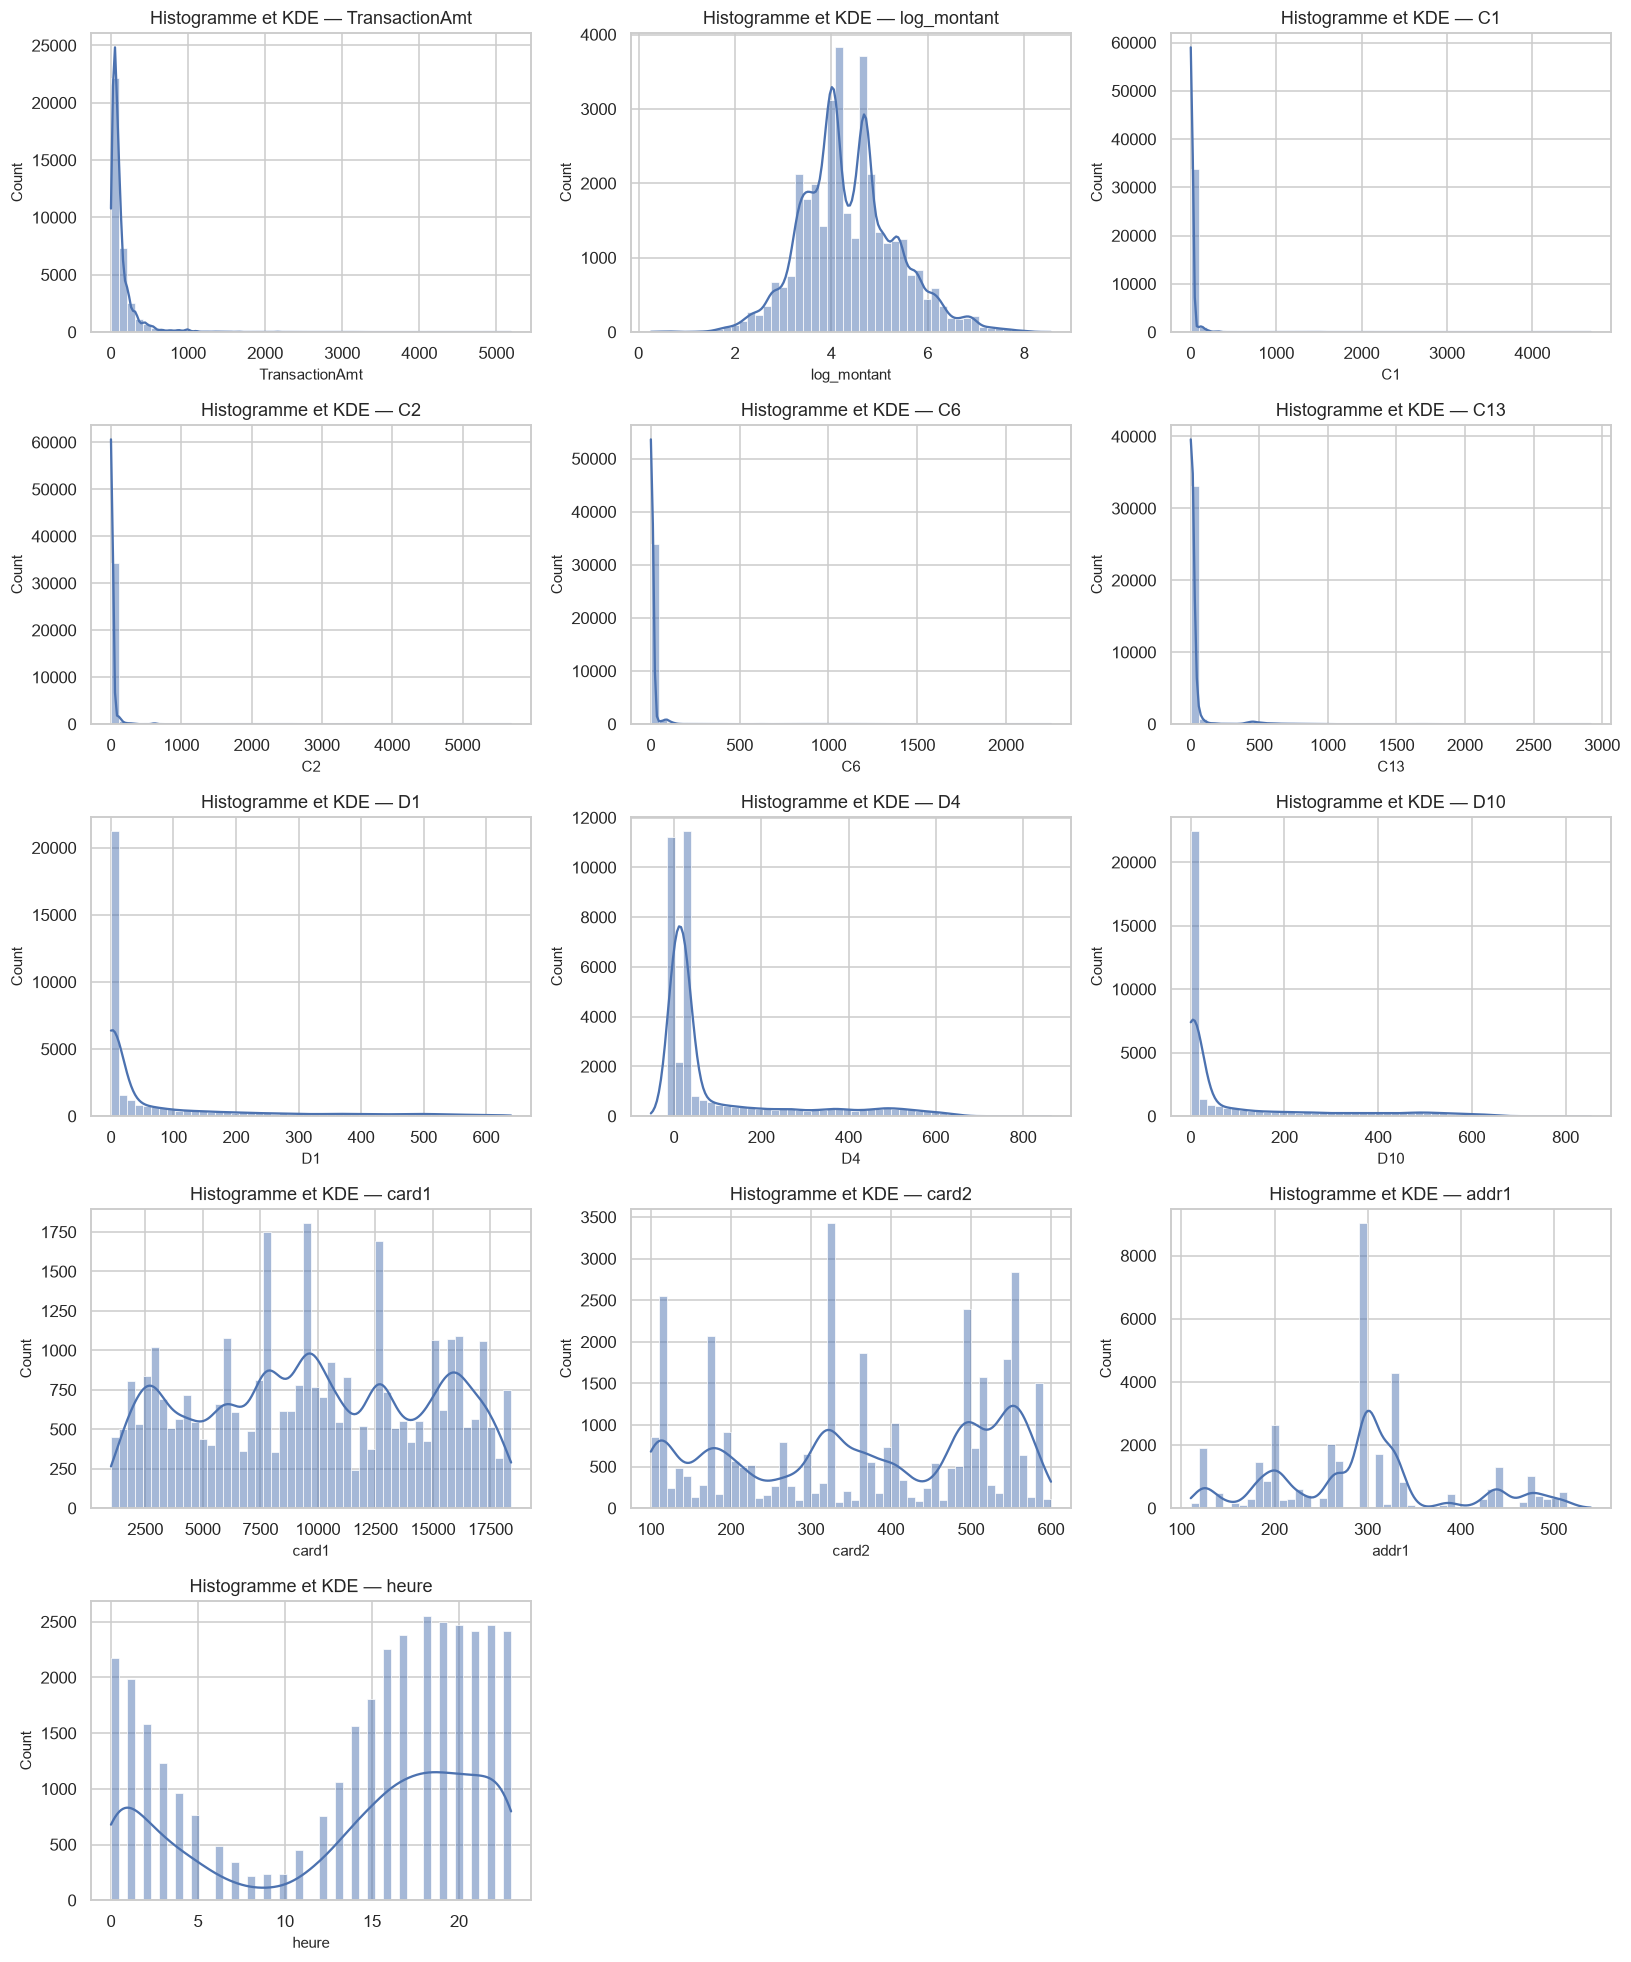

In [46]:
# Histogrammes + KDE
n = len(cols_num)
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(15, 3.6 * ((n + 2) // 3)))
for ax, c in zip(axes.ravel(), cols_num):
    sns.histplot(df_s[c], bins=50, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"Histogramme et KDE — {c}")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interprétation — Histogrammes et KDE

La plupart des distributions sont concentrées près de zéro avec une longue queue à droite ; certaines variables (heure) présentent un profil cyclique, d'autres (card1, addr1) sont des codes dont la distribution n'a pas de sens métrique.

L'allure unimodale très asymétrique indique des lois de type log-normale ou de comptage ; la loi normale n'est pas un modèle adapté (confirmé par les tests de normalité plus loin).

Les profils d'activité horaire peuvent orienter la surveillance (renforcement des contrôles sur les plages à risque).

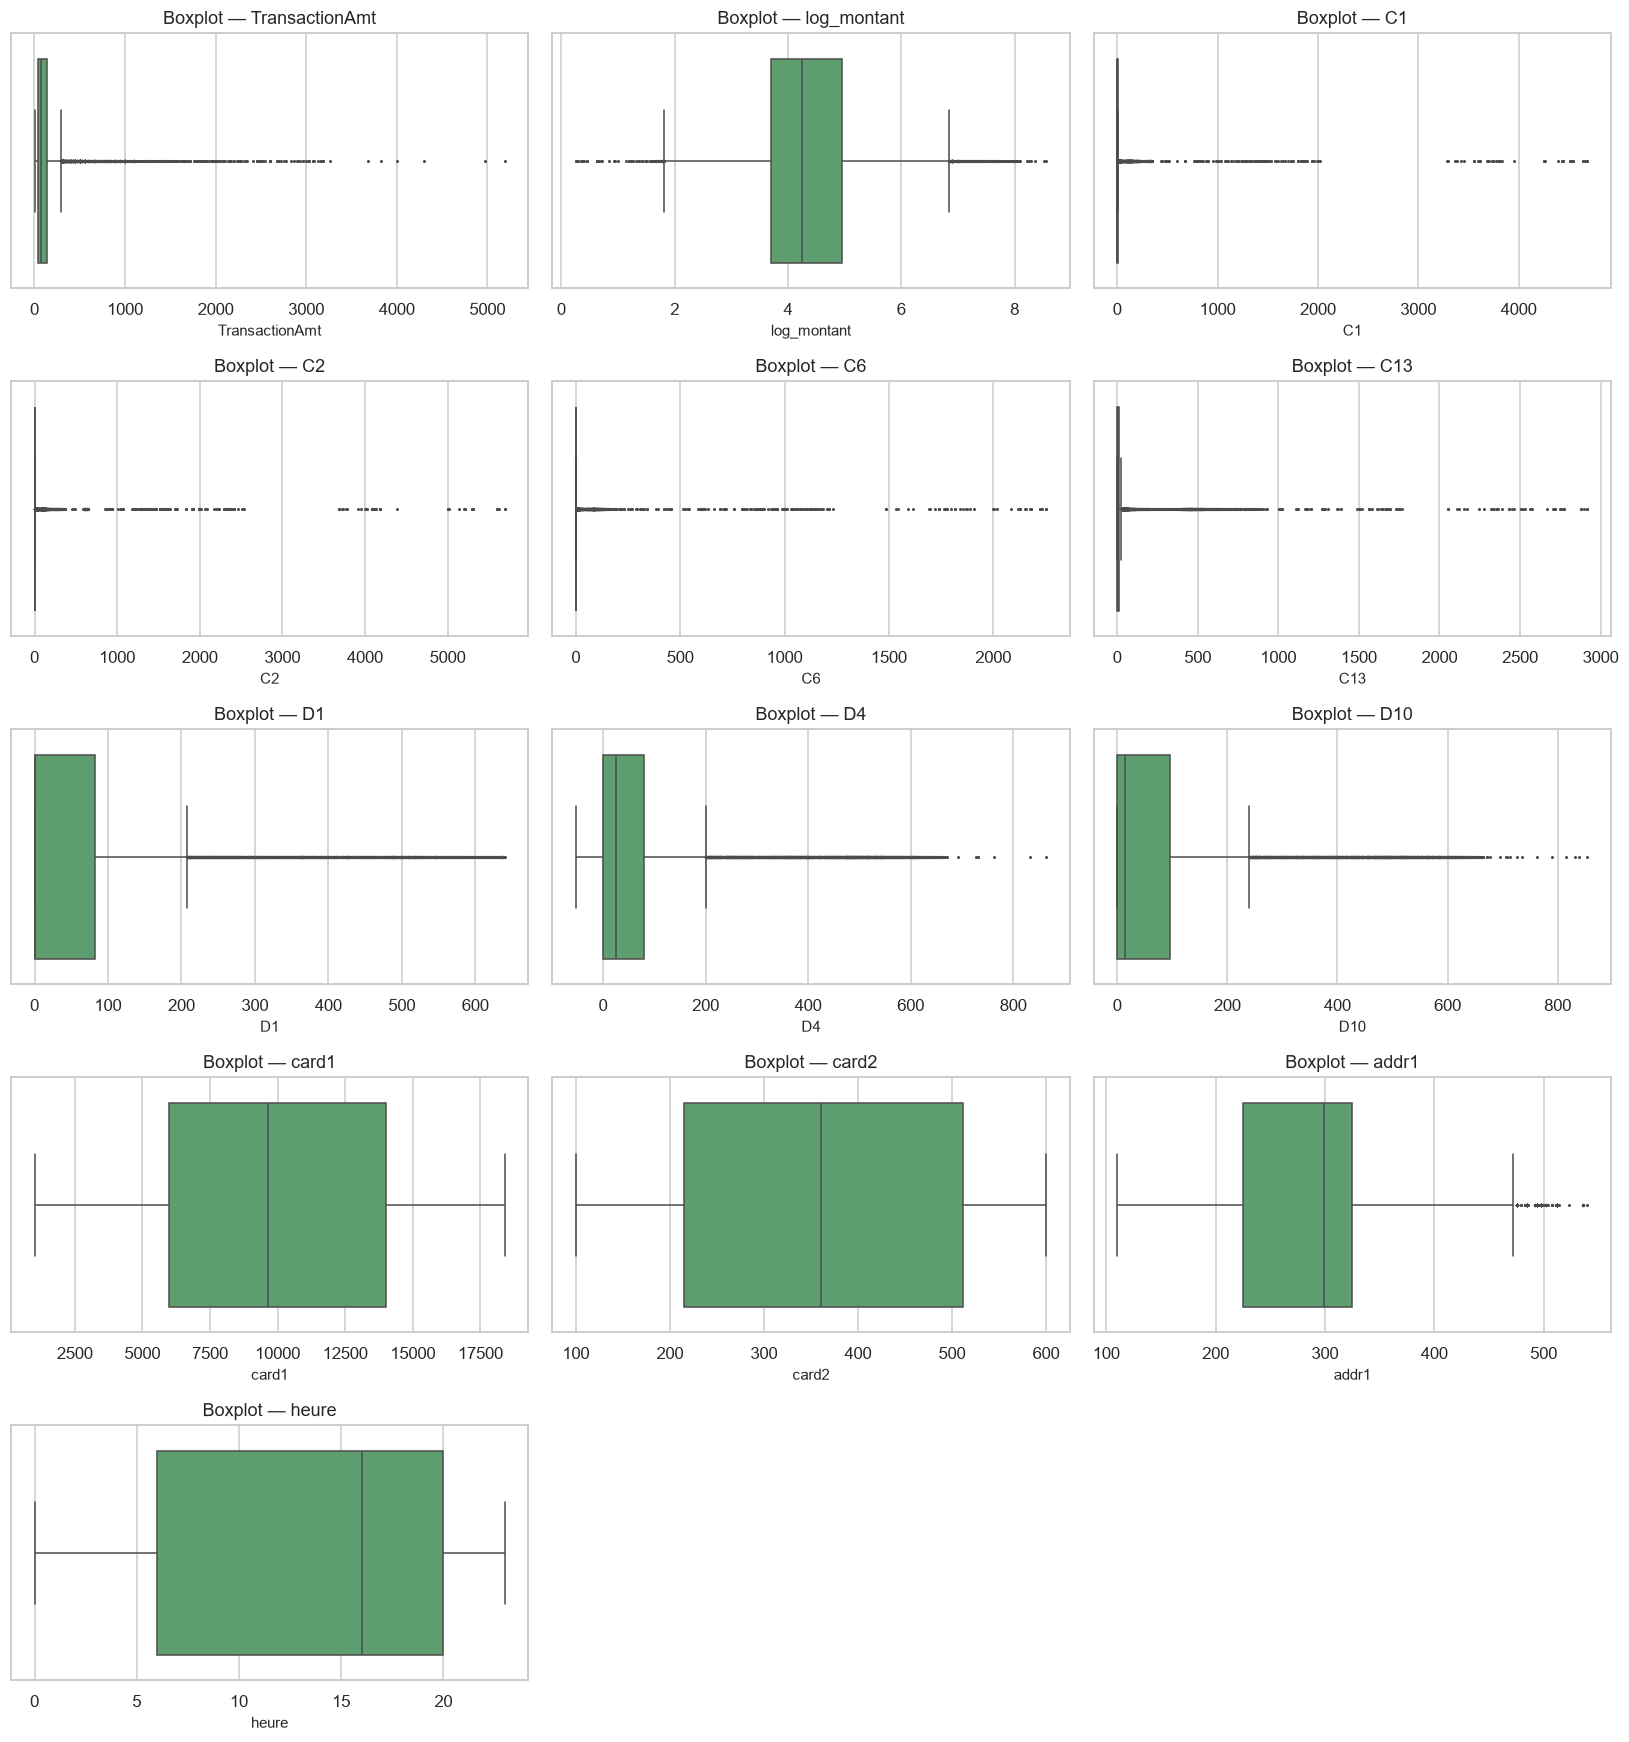

In [47]:
# Boxplots
fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(15, 3.2 * ((n + 2) // 3)))
for ax, c in zip(axes.ravel(), cols_num):
    sns.boxplot(x=df_s[c], ax=ax, color="#55A868", fliersize=1)
    ax.set_title(f"Boxplot — {c}")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Interprétation — Boxplots

Les boîtes sont comprimées vers la gauche et un grand nombre de points se situent au-delà de la moustache droite.

L'écart interquartile est faible relativement à l'étendue des données : les valeurs extrêmes sont nombreuses mais correspondent à des comportements réels, comme établi au chapitre 3.

Ces valeurs extrêmes méritent une attention particulière : elles sont à la fois le lieu où se cachent des fraudes et celui où se trouvent les gros clients légitimes.

### 4.1.3 Variables catégorielles

In [48]:
cols_cat = [c for c in ["ProductCD", "card4", "card6", "DeviceType", "P_emaildomain", "categorie_montant"] if c in df.columns]

# Fréquences (jeu complet)
for c in cols_cat:
    freq = df[c].value_counts().to_frame("effectif")
    freq["pourcentage"] = (df[c].value_counts(normalize=True) * 100).round(2)
    print(f"--- {c} ({df[c].nunique()} modalités) ---")
    display(freq.head(8))

--- ProductCD (5 modalités) ---


,effectif,pourcentage
ProductCD,,
W,439670,74.450
C,68519,11.600
R,37699,6.380
H,33024,5.590
S,11628,1.970


--- card4 (4 modalités) ---


,effectif,pourcentage
card4,,
visa,386344,65.420
mastercard,189217,32.040
american express,8328,1.410
discover,6651,1.130


--- card6 (4 modalités) ---


,effectif,pourcentage
card6,,
debit,441509,74.760
credit,148986,25.230
debit or credit,30,0.010
charge card,15,0.000


... (2 outputs left out)

--- P_emaildomain (59 modalités) ---


,effectif,pourcentage
P_emaildomain,,
gmail.com,322811,54.660
yahoo.com,100934,17.090
hotmail.com,45250,7.660
anonymous.com,36998,6.270
aol.com,28289,4.790
comcast.net,7888,1.340
icloud.com,6267,1.060
outlook.com,5096,0.860


--- categorie_montant (5 modalités) ---


,effectif,pourcentage
categorie_montant,,
Faible,124763,21.130
Moyen,122695,20.780
Très faible,121161,20.520
Très élevé,117443,19.890
Élevé,104478,17.690


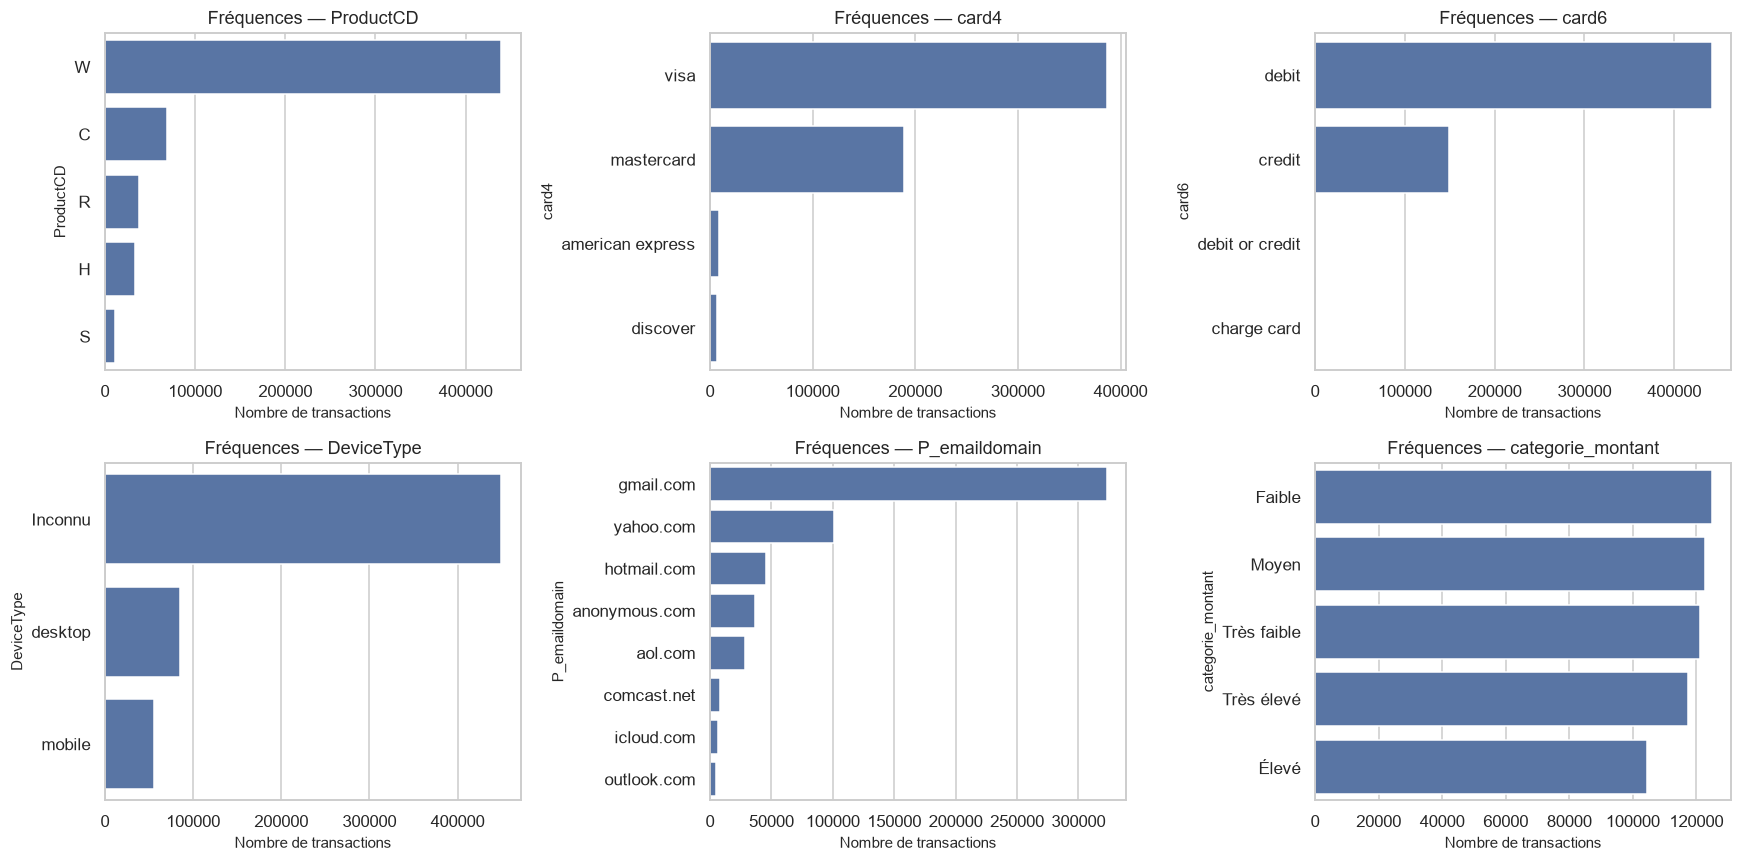

In [49]:
# Countplots
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), cols_cat):
    ordre = df[c].value_counts().head(8).index
    sns.countplot(data=df[df[c].isin(ordre)], y=c, order=ordre, ax=ax, color="#4C72B0")
    ax.set_title(f"Fréquences — {c}")
    ax.set_xlabel("Nombre de transactions")
plt.tight_layout()
plt.show()

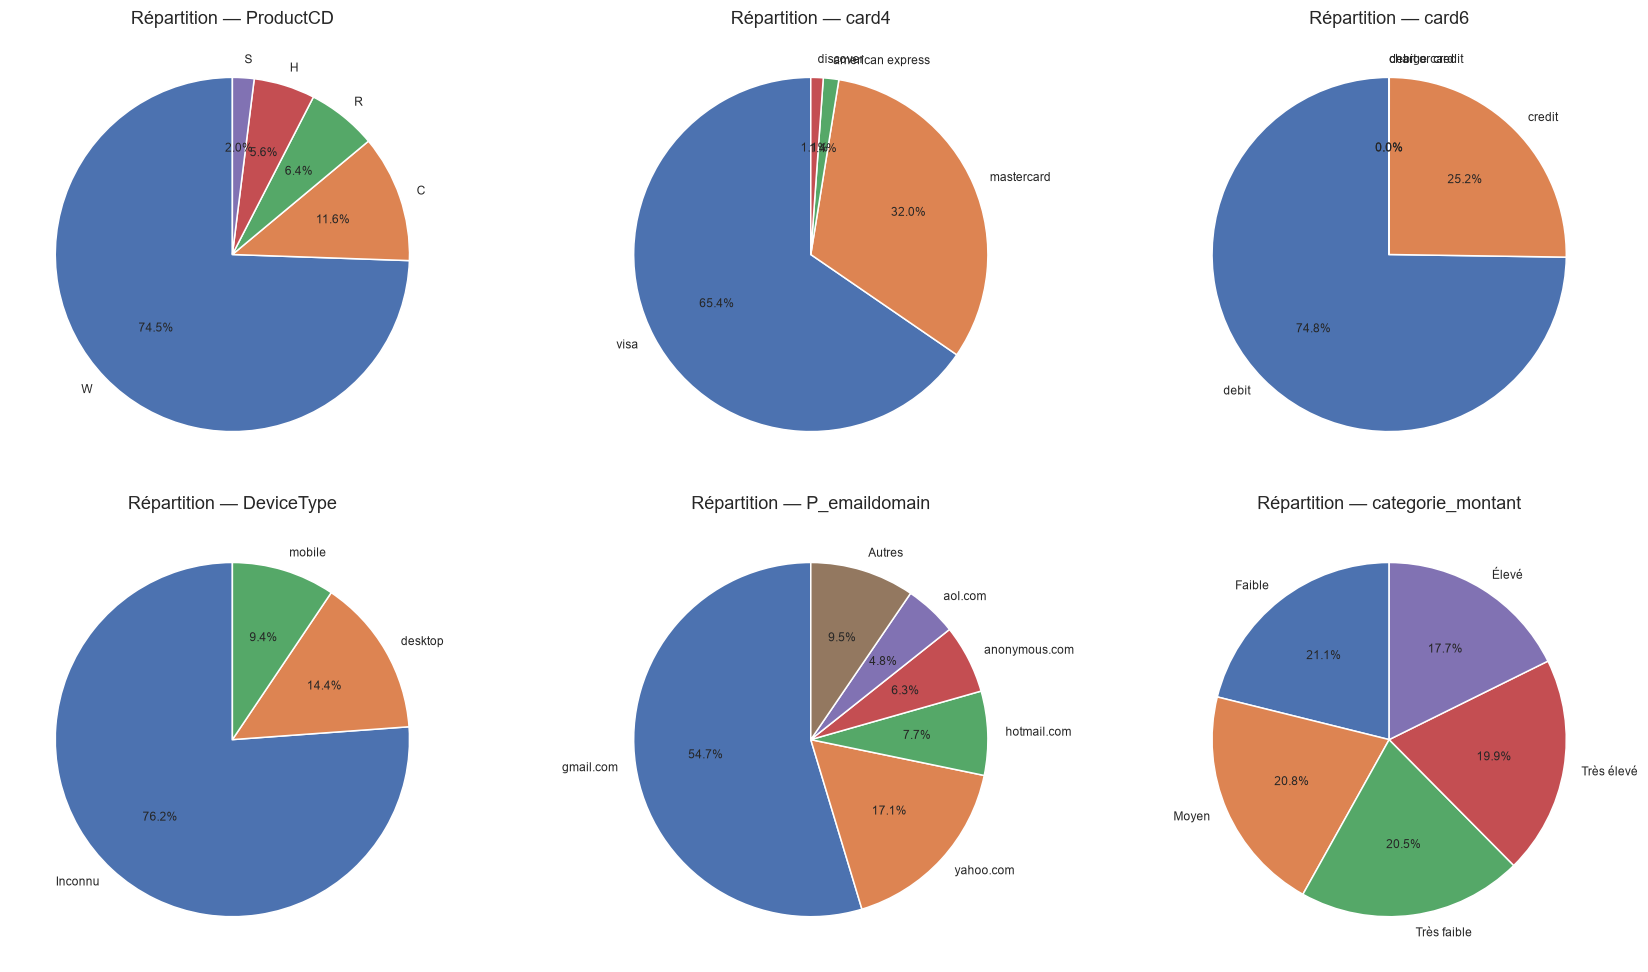

In [50]:
# Diagrammes circulaires (modalités principales, le reste regroupé en « Autres »)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), cols_cat):
    p = df[c].value_counts(normalize=True)
    p = pd.concat([p.head(5), pd.Series({"Autres": p.iloc[5:].sum()})]) if len(p) > 5 else p
    ax.pie(p, labels=p.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("deep"),
           textprops={"fontsize": 8})
    ax.set_title(f"Répartition — {c}")
plt.tight_layout()
plt.show()

### Interprétation — Variables catégorielles

Les variables catégorielles sont très inégalement réparties : une ou deux modalités dominent (par exemple un code produit, un réseau de carte, un type de carte, quelques domaines email très répandus). DeviceType compte une forte proportion de « Inconnu » issue de l'absence d'information d'identité.

Les modalités rares sont statistiquement peu stables : elles devront être regroupées avant les tests du Khi-deux (effectifs théoriques ≥ 5) et avant l'encodage.

La répartition par produit, réseau de carte et domaine email permet d'identifier les canaux et partenaires les plus exposés.

### 4.1.4 Variable cible : répartition et déséquilibre

         effectif  pourcentage
isFraud                       
0          569877       96.501
1           20663        3.499

Ratio légitimes / fraudes : 27.6 pour 1


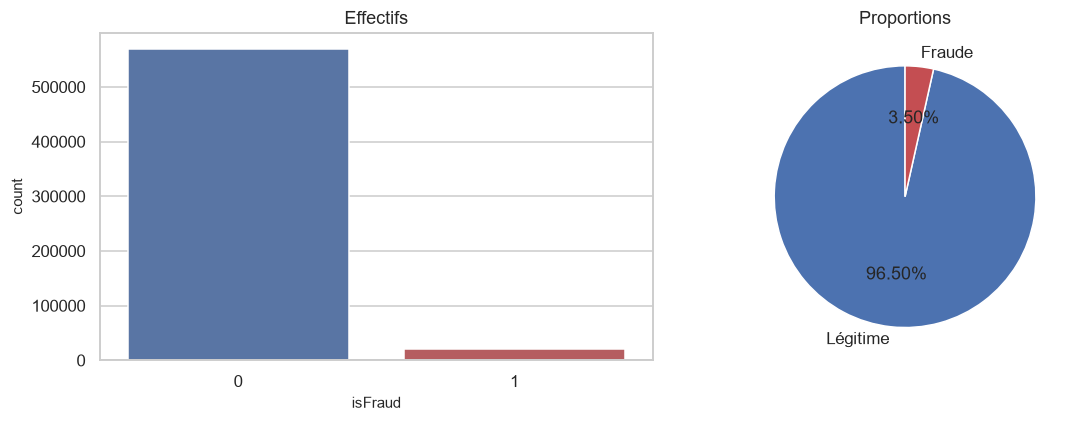

In [51]:
cible = df["isFraud"].value_counts()
ratio = cible[0] / cible[1]
print(cible.to_frame("effectif").assign(pourcentage=(cible / len(df) * 100).round(3)))
print(f"\nRatio légitimes / fraudes : {ratio:.1f} pour 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="isFraud", data=df, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Effectifs")
axes[1].pie(cible, labels=["Légitime", "Fraude"], autopct="%1.2f%%", colors=["#4C72B0", "#C44E52"], startangle=90)
axes[1].set_title("Proportions")
plt.tight_layout()
plt.show()

### Interprétation — Variable cible

La classe fraude ne représente qu'environ 3,5 % des transactions (ratio d'environ 27 pour 1).

Le déséquilibre est fort : l'accuracy est trompeuse, un modèle naïf atteint 96,5 %. Il faudra utiliser des métriques adaptées (précision, rappel, F1, AUC-PR) et des techniques de rééquilibrage (pondération des classes, SMOTE, sous-échantillonnage).

Un rappel élevé limite les pertes financières, mais une précision trop faible génère de nombreuses fausses alertes coûteuses en traitement et en satisfaction client.

## 4.2 ANALYSE BIVARIÉE

### 4.2.1 TransactionAmt vs isFraud

,count,mean,std,min,25%,50%,75%,95%,max
isFraud,,,,,,,,,
0,"569,877.000",134.512,239.395,0.251,43.970,68.500,120.000,435.000,"31,937.391"
1,"20,663.000",149.245,232.212,0.292,35.044,75.000,161.000,500.000,"5,191.000"


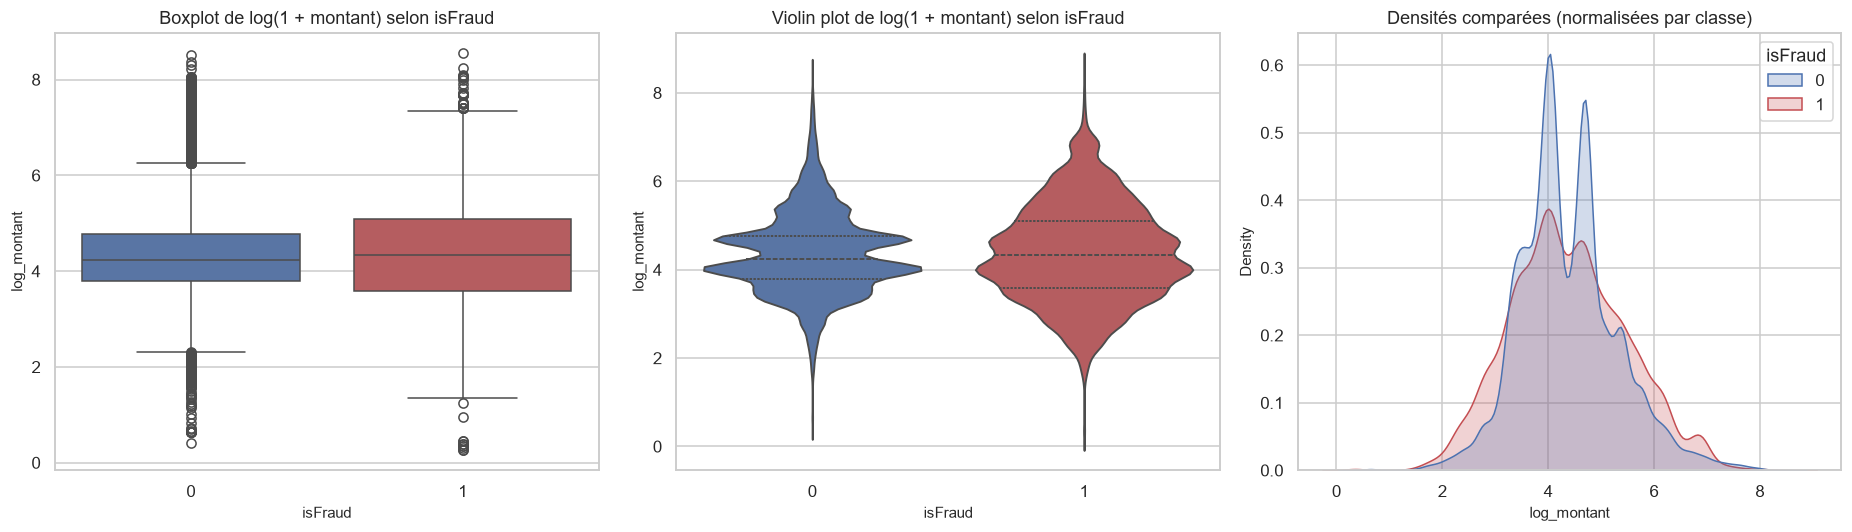

In [52]:
# Statistiques par classe (jeu complet)
display(df.groupby("isFraud")["TransactionAmt"].describe(percentiles=[.25, .5, .75, .95]))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=df_s, x="isFraud", y="log_montant", ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Boxplot de log(1 + montant) selon isFraud")
sns.violinplot(data=df_s, x="isFraud", y="log_montant", ax=axes[1], palette=["#4C72B0", "#C44E52"], inner="quartile")
axes[1].set_title("Violin plot de log(1 + montant) selon isFraud")
sns.kdeplot(data=df_s, x="log_montant", hue="isFraud", common_norm=False, fill=True, ax=axes[2], palette=["#4C72B0", "#C44E52"])
axes[2].set_title("Densités comparées (normalisées par classe)")
plt.tight_layout()
plt.show()

### Interprétation — TransactionAmt vs isFraud

Les distributions des montants des transactions légitimes et frauduleuses se chevauchent largement ; les statistiques par classe et les densités montrent toutefois des différences de position et de forme.

Le montant seul n'est pas un critère discriminant fort : aucune frontière simple ne sépare les deux classes. La significativité statistique de l'écart sera testée formellement (Student, Mann-Whitney).

Il est inutile de fonder une règle de blocage sur le seul montant : le risque de fausses alertes serait élevé. Le montant est un signal parmi d'autres à combiner avec les attributs d'appareil, de carte et de comportement.

### 4.2.2 ProductCD vs isFraud

,count,sum,taux_fraude_%
ProductCD,,,
C,68519,8008,11.687
S,11628,686,5.900
H,33024,1574,4.766
R,37699,1426,3.783
W,439670,8969,2.040


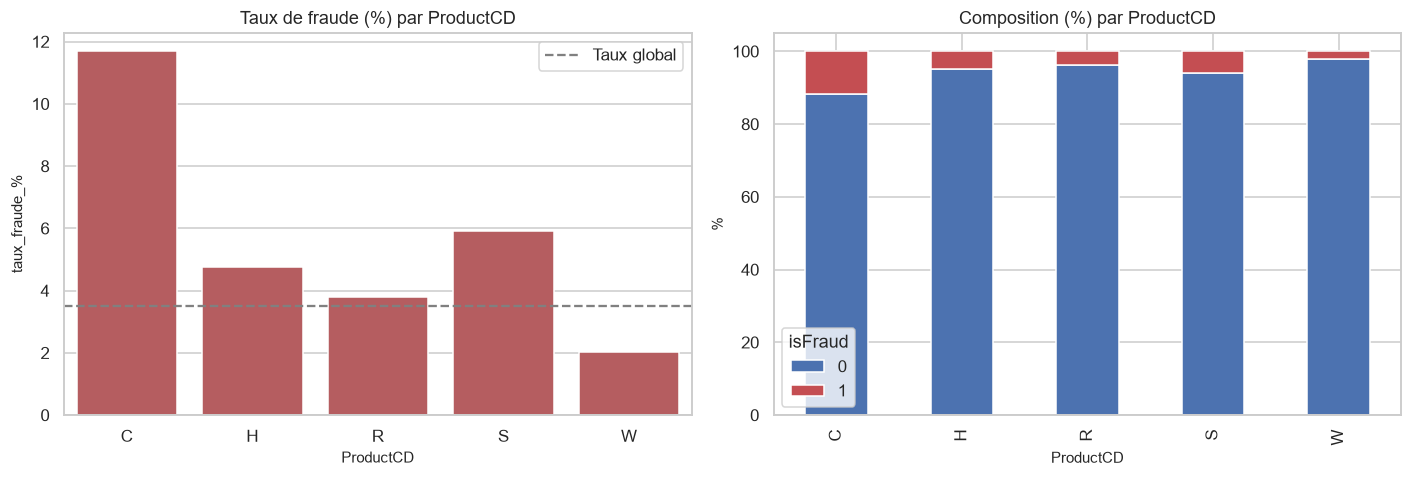

In [53]:
# Taux de fraude par code produit (jeu complet)
tx_produit = df.groupby("ProductCD")["isFraud"].agg(["count", "sum", "mean"])
tx_produit["taux_fraude_%"] = tx_produit["mean"] * 100
display(tx_produit.sort_values("taux_fraude_%", ascending=False).drop(columns="mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=tx_produit.reset_index(), x="ProductCD", y="taux_fraude_%", ax=axes[0], color="#C44E52")
axes[0].axhline(df["isFraud"].mean() * 100, ls="--", color="grey", label="Taux global")
axes[0].set_title("Taux de fraude (%) par ProductCD")
axes[0].legend()
pd.crosstab(df["ProductCD"], df["isFraud"], normalize="index").mul(100).plot(kind="bar", stacked=True, ax=axes[1], color=["#4C72B0", "#C44E52"])
axes[1].set_title("Composition (%) par ProductCD")
axes[1].set_ylabel("%")
plt.tight_layout()
plt.show()

### Interprétation — ProductCD vs isFraud

Le taux de fraude diffère sensiblement d'un code produit à l'autre : certains codes dépassent largement le taux global (environ 3,5 %), d'autres sont nettement en dessous.

Le type de produit est associé au risque de fraude. L'association est à confirmer par le test du Khi-deux et mesurer par le V de Cramer, mais l'écart visuel est déjà important.

Les canaux et produits les plus exposés peuvent faire l'objet de contrôles renforcés (authentification forte, seuils d'alerte plus bas).

### 4.2.3 DeviceType vs isFraud

,count,sum,taux_fraude_%
DeviceType,,,
Inconnu,449730,9452,2.102
desktop,85165,5554,6.521
mobile,55645,5657,10.166


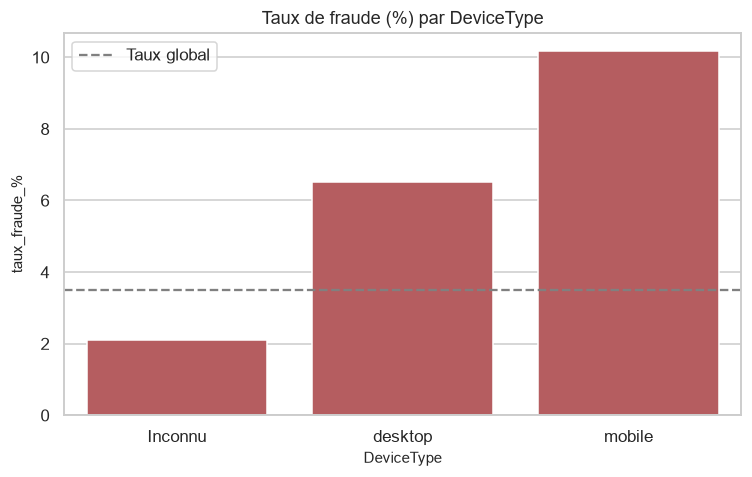

In [54]:
tx_device = df.groupby("DeviceType")["isFraud"].agg(["count", "sum", "mean"])
tx_device["taux_fraude_%"] = tx_device["mean"] * 100
display(tx_device.drop(columns="mean"))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(data=tx_device.reset_index(), x="DeviceType", y="taux_fraude_%", ax=ax, color="#C44E52")
ax.axhline(df["isFraud"].mean() * 100, ls="--", color="grey", label="Taux global")
ax.set_title("Taux de fraude (%) par DeviceType")
ax.legend()
plt.tight_layout()
plt.show()

### Interprétation — DeviceType vs isFraud

Les transactions pour lesquelles l'appareil est connu (mobile ou desktop) présentent un taux de fraude plus élevé que celles pour lesquelles l'information est absente (« Inconnu »), et mobile et desktop diffèrent entre eux.

L'existence d'une information d'identité est elle-même corrélée à la fraude, ce qui valide la création de l'indicateur has_identity. Attention : « Inconnu » regroupe des transactions sans collecte d'identité, non des transactions sans appareil.

Les analystes fraude peuvent surveiller séparément les parcours mobile et desktop et vérifier la qualité de la collecte des données d'appareil.

### 4.2.4 Variables numériques entre elles

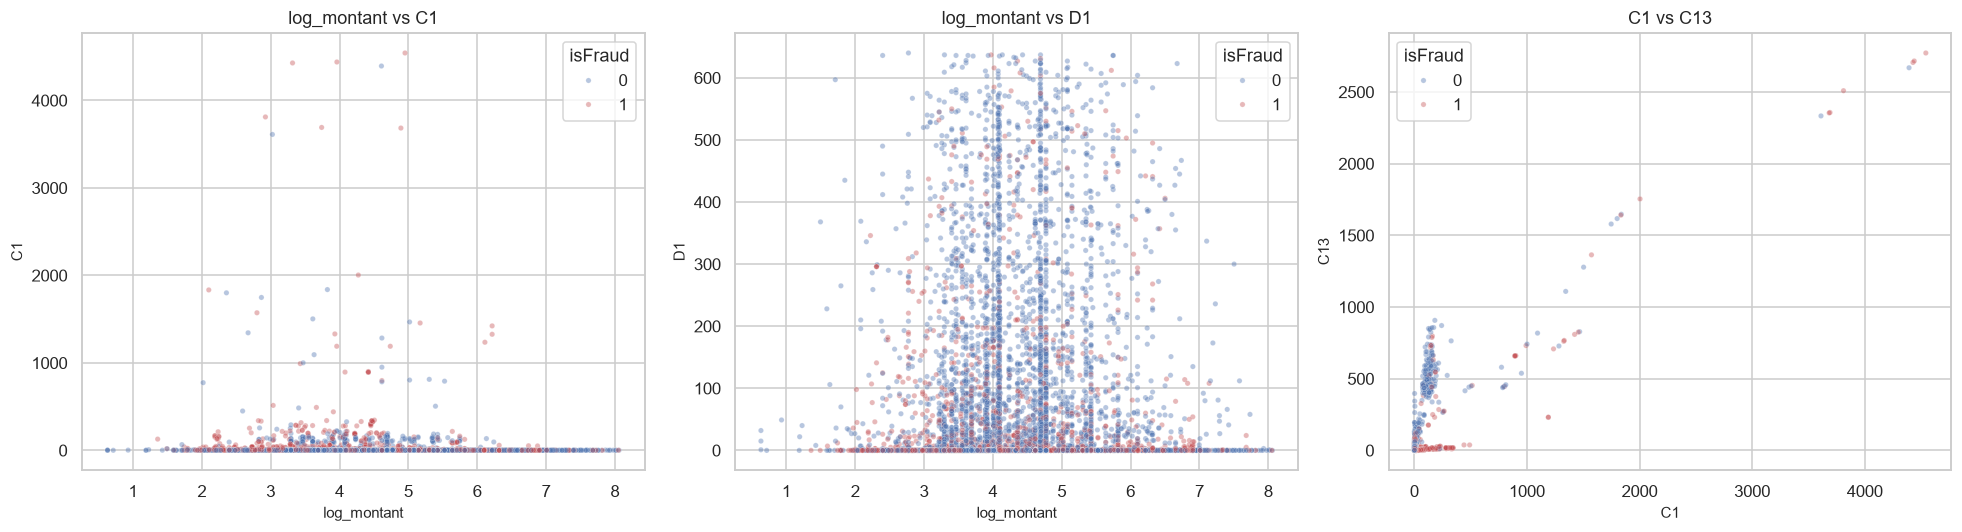

In [55]:
# Scatterplots (échantillon) : relations entre variables numériques
paires = [("log_montant", "C1"), ("log_montant", "D1"), ("C1", "C13")]
paires = [(a, b) for a, b in paires if a in df_s.columns and b in df_s.columns]

fig, axes = plt.subplots(1, len(paires), figsize=(6 * len(paires), 5))
axes = np.atleast_1d(axes)
for ax, (a, b) in zip(axes, paires):
    sns.scatterplot(data=df_s.sample(8000, random_state=SEED), x=a, y=b, hue="isFraud", alpha=0.4, s=12,
                    palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(f"{a} vs {b}")
plt.tight_layout()
plt.show()

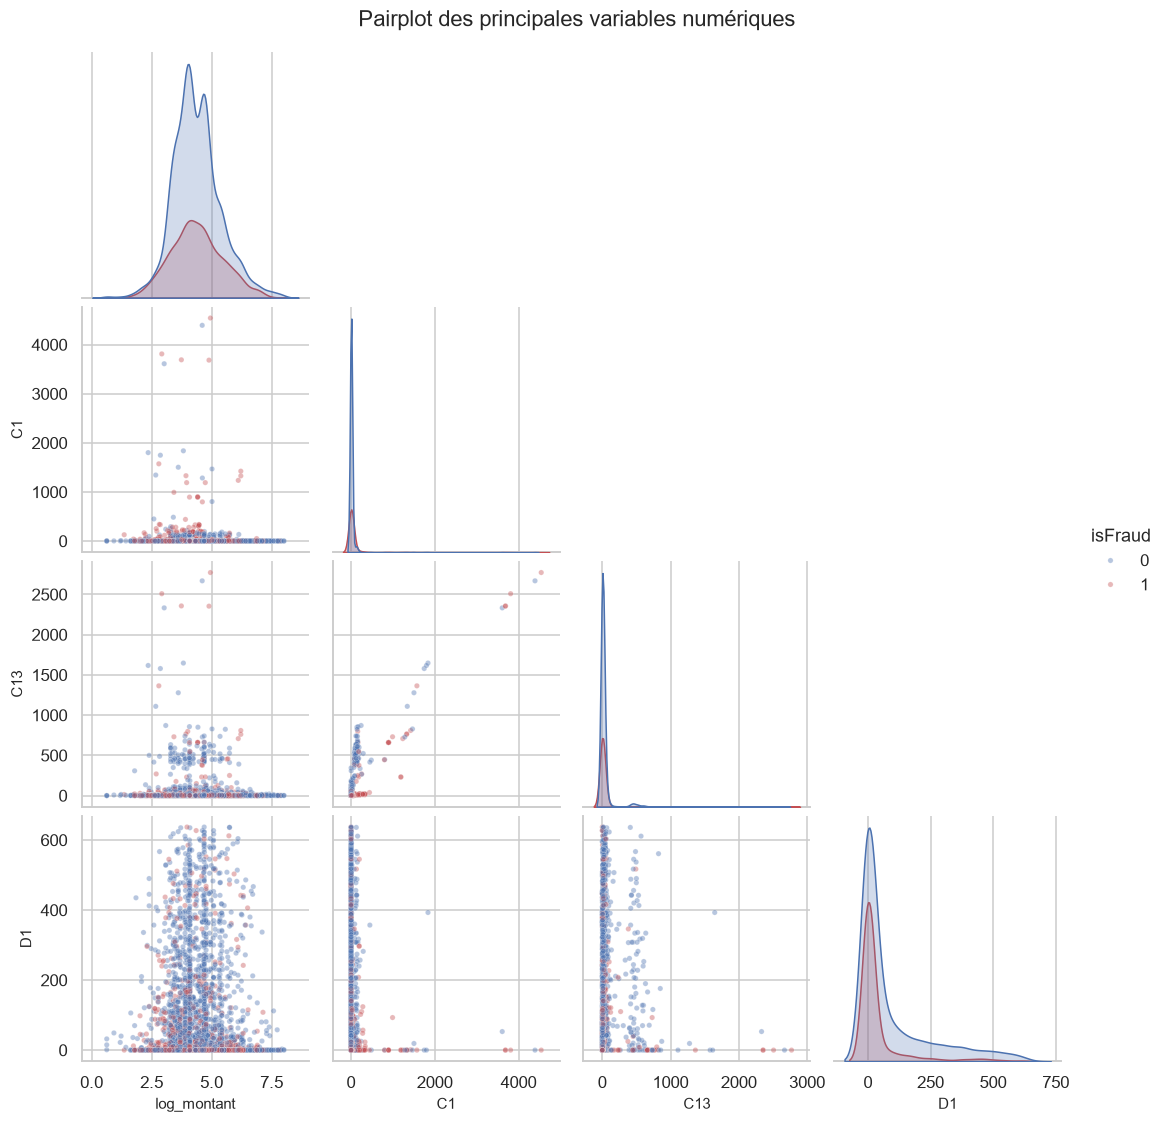

In [56]:
# Pairplot sur un sous-ensemble de variables
cols_pair = [c for c in ["log_montant", "C1", "C13", "D1", "dist1"] if c in df.columns][:5]
g = sns.pairplot(df_s.sample(4000, random_state=SEED), vars=cols_pair, hue="isFraud",
                 palette=["#4C72B0", "#C44E52"], plot_kws={"alpha": 0.4, "s": 12}, diag_kind="kde", corner=True)
g.fig.suptitle("Pairplot des principales variables numériques", y=1.02)
plt.show()

### Interprétation — Variables numériques entre elles

Les nuages de points montrent des structures marquées : concentration près de l'origine, dépendance positive entre certains comptages (C1, C13) et alignements dus au caractère discret des variables. Les fraudes (en rouge) se mêlent aux transactions légitimes sans zone isolée.

Certaines variables sont liées linéairement ou monotonement, ce qui annonce de la redondance (à confirmer par la matrice de corrélation). L'absence de séparation visuelle nette confirme qu'une modélisation multivariée est nécessaire.

Aucun couple de variables ne permet à lui seul de repérer la fraude : la détection exige un modèle combinant de nombreux signaux.

## 4.3 TESTS STATISTIQUES

Seuil de signification pour tous les tests : **α = 5 %**. Règle de décision : on rejette H0 si **p-value < 0,05**.

### 4.3.1 Normalité — Shapiro-Wilk

**H0** : la variable suit une loi normale.
**H1** : la variable ne suit pas une loi normale.
**Règle de décision** : si p-value < 0,05, on rejette H0 ; sinon on ne la rejette pas.

Remarque : Shapiro-Wilk est calibré pour n ≤ 5 000 ; au-delà, la p-value n'est plus fiable. Le test est donc appliqué sur un échantillon aléatoire de 5 000 observations.

In [57]:
vars_norm = [c for c in ["TransactionAmt", "log_montant", "C1", "D1"] if c in df.columns]
echant = df.sample(5000, random_state=SEED)

res_shapiro = []
for c in vars_norm:
    W, p = stats.shapiro(echant[c])
    res_shapiro.append([c, W, p, "Rejet de H0 (non normale)" if p < ALPHA else "H0 non rejetée"])
pd.DataFrame(res_shapiro, columns=["Variable", "Statistique W", "p-value", "Décision (α = 5 %)"])

,Variable,Statistique W,p-value,Décision (α = 5 %)
0,TransactionAmt,0.468,0.000,Rejet de H0 (non normale)
1,log_montant,0.982,0.000,Rejet de H0 (non normale)
2,C1,0.063,0.000,Rejet de H0 (non normale)
3,D1,0.650,0.000,Rejet de H0 (non normale)


### Interprétation — Test de Shapiro-Wilk

Les p-values sont très inférieures à 0,05 pour toutes les variables testées : H0 est rejetée. La statistique W est la plus proche de 1 pour log_montant, indiquant que la transformation logarithmique rapproche la distribution de la normalité sans l'atteindre.

Aucune de ces variables n'est normale. Sur de grands échantillons, même de petits écarts à la normalité sont significatifs, mais ici l'asymétrie est massive.

Les méthodes reposant sur la normalité (test t, ACP sur variables brutes) doivent être employées avec précaution ou complétées par des méthodes non paramétriques.

### 4.3.2 Normalité — Kolmogorov-Smirnov

**H0** : la variable suit une loi normale de moyenne et d'écart-type estimés sur l'échantillon.
**H1** : la variable ne suit pas cette loi normale.
**Règle de décision** : on rejette H0 si p-value < 0,05.

Les variables sont standardisées avant comparaison à N(0, 1). Sans correction de Lilliefors, la p-value est approximative (conservatrice) ; on l'utilise à titre de confirmation.

In [58]:
res_ks = []
for c in vars_norm:
    x = df[c]
    stat, p = stats.kstest((x - x.mean()) / x.std(), "norm")
    res_ks.append([c, stat, p, "Rejet de H0 (non normale)" if p < ALPHA else "H0 non rejetée"])
pd.DataFrame(res_ks, columns=["Variable", "Statistique D", "p-value", "Décision (α = 5 %)"])

,Variable,Statistique D,p-value,Décision (α = 5 %)
0,TransactionAmt,0.291,0.000,Rejet de H0 (non normale)
1,log_montant,0.097,0.000,Rejet de H0 (non normale)
2,C1,0.460,0.000,Rejet de H0 (non normale)
3,D1,0.275,0.000,Rejet de H0 (non normale)


### Interprétation — Test de Kolmogorov-Smirnov

Les p-values sont quasi nulles : H0 est rejetée pour toutes les variables, ce qui confirme Shapiro-Wilk.

Les deux tests convergent : les distributions s'écartent significativement de la loi normale.

On privilégie des tests non paramétriques (Mann-Whitney) et des modèles qui ne supposent pas de normalité (arbres, ensembles).

### 4.3.3 Comparaison de moyennes — Student

Variable testée : **log(1 + TransactionAmt)** (transformation qui rend le test t plus défendable, étant donné la taille des échantillons).

**H0** : μ(fraude) = μ(légitime)
**H1** : μ(fraude) ≠ μ(légitime)
**Statistique** : t = (x̄₁ − x̄₂) / (s_p · √(1/n₁ + 1/n₂))
**Règle de décision** : on rejette H0 si p-value < 0,05.

Le test de Student suppose l'égalité des variances ; on la vérifie au préalable avec le test de Levene.

In [59]:
fraude = df.loc[df["isFraud"] == 1, "log_montant"]
legit  = df.loc[df["isFraud"] == 0, "log_montant"]

# Égalité des variances (Levene) : H0 = variances égales
lev_stat, lev_p = stats.levene(fraude, legit)
print(f"Levene : stat = {lev_stat:.3f}, p-value = {lev_p:.4g}")

# Test de Student (variances égales) et variante de Welch si Levene rejeté
t_stat, t_p = stats.ttest_ind(fraude, legit, equal_var=True)
w_stat, w_p = stats.ttest_ind(fraude, legit, equal_var=False)

print(f"Student : t = {t_stat:.3f}, p-value = {t_p:.4g}")
print(f"Welch   : t = {w_stat:.3f}, p-value = {w_p:.4g}")
print(f"\nMoyenne log-montant : fraude = {fraude.mean():.3f} | légitime = {legit.mean():.3f}")
print("Décision :", "Rejet de H0" if t_p < ALPHA else "H0 non rejetée")

Levene : stat = 1479.289, p-value = 0
Student : t = -1.375, p-value = 0.1692
Welch   : t = -1.172, p-value = 0.2412

Moyenne log-montant : fraude = 4.374 | légitime = 4.383
Décision : H0 non rejetée


### Interprétation — Test de Student

Avec des échantillons de plusieurs centaines de milliers d'observations, la p-value est généralement très faible et H0 est rejetée : les moyennes de log-montant diffèrent significativement entre fraudes et transactions légitimes (la variante de Welch, robuste à l'inégalité des variances, donne la même conclusion).

Significatif ne veut pas dire important : la taille d'échantillon rend détectables de petits écarts. L'amplitude de la différence (écart des moyennes en log) est modeste.

Le montant a un effet réel mais de faible ampleur sur la probabilité de fraude : il doit être combiné à d'autres variables plutôt qu'utilisé seul.

### 4.3.4 Comparaison non paramétrique — Mann-Whitney

**H0** : les distributions de TransactionAmt sont identiques pour les fraudes et les transactions légitimes (P(X_fraude > X_légitime) = 0,5).
**H1** : les distributions diffèrent (l'une est stochastiquement plus grande).
**Règle de décision** : on rejette H0 si p-value < 0,05.

Ce test ne suppose ni normalité ni égalité des variances et convient aux distributions fortement asymétriques.

In [60]:
x_f = df.loc[df["isFraud"] == 1, "TransactionAmt"]
x_l = df.loc[df["isFraud"] == 0, "TransactionAmt"]

U, p_mw = stats.mannwhitneyu(x_f, x_l, alternative="two-sided")
# Taille d'effet : probabilité de supériorité (common language effect size)
cles = U / (len(x_f) * len(x_l))

print(f"Mann-Whitney U = {U:,.0f}, p-value = {p_mw:.4g}")
print(f"Probabilité qu'une fraude ait un montant supérieur à une transaction légitime : {cles:.3f}")
print(f"Médiane fraude = {x_f.median():.2f} | médiane légitime = {x_l.median():.2f}")
print("Décision :", "Rejet de H0" if p_mw < ALPHA else "H0 non rejetée")

Mann-Whitney U = 5,858,540,544, p-value = 0.2259
Probabilité qu'une fraude ait un montant supérieur à une transaction légitime : 0.498
Médiane fraude = 75.00 | médiane légitime = 68.50
Décision : H0 non rejetée


### Interprétation — Test de Mann-Whitney

H0 est rejetée (p-value très faible) : la distribution des montants diffère entre fraudes et transactions légitimes. La probabilité de supériorité reste proche de 0,5, ce qui indique un effet de faible ampleur.

Le résultat confirme le test de Student sans dépendre de la normalité. Les deux classes diffèrent en distribution, mais le recouvrement est important.

Le montant est un indicateur utile mais insuffisant ; il ne justifie pas à lui seul des règles de blocage.

### 4.3.5 Indépendance — Khi-deux

**H0** : la variable catégorielle est indépendante de isFraud.
**H1** : la variable catégorielle et isFraud sont dépendantes.
**Statistique** : χ² = Σ (Observé − Théorique)² / Théorique, avec ddl = (r − 1)(c − 1).
**Règle de décision** : on rejette H0 si p-value < 0,05.

Condition de validité : effectifs théoriques ≥ 5 (vérifiée ci-dessous).

In [61]:
vars_chi2 = [c for c in ["ProductCD", "card4", "card6", "DeviceType", "categorie_montant"] if c in df.columns]

res_chi2 = []
for c in vars_chi2:
    table = pd.crosstab(df[c], df["isFraud"])
    chi2, p, ddl, attendus = chi2_contingency(table)
    res_chi2.append([c, chi2, ddl, p, (attendus >= 5).all(),
                     "Rejet de H0 (dépendance)" if p < ALPHA else "H0 non rejetée"])
tab_chi2 = pd.DataFrame(res_chi2, columns=["Variable", "χ²", "ddl", "p-value", "Effectifs théoriques ≥ 5", "Décision (α = 5 %)"])
tab_chi2

,Variable,χ²,ddl,p-value,Effectifs théoriques ≥ 5,Décision (α = 5 %)
0,ProductCD,"16,742.172",4,0.000,True,Rejet de H0 (dépendance)
1,card4,365.335,3,0.000,True,Rejet de H0 (dépendance)
2,card6,"5,966.287",3,0.000,False,Rejet de H0 (dépendance)
3,DeviceType,"12,230.166",2,0.000,True,Rejet de H0 (dépendance)
4,categorie_montant,"1,092.976",4,0.000,True,Rejet de H0 (dépendance)


### Interprétation — Test du Khi-deux

Pour la plupart des variables testées, la p-value est quasi nulle et H0 est rejetée : ProductCD, card4, card6, DeviceType et la catégorie de montant sont liés à isFraud. Les conditions d'application (effectifs théoriques) sont satisfaites.

Le Khi-deux détecte l'existence d'une dépendance mais pas son intensité, d'autant plus que la taille de l'échantillon (590 000 lignes) rend significatif le moindre écart. Il faut compléter par une mesure d'effet (V de Cramer).

Les variables dépendantes de la fraude sont candidates à la modélisation et aux règles métier.

### 4.3.6 Association — V de Cramer

**H0** : V = 0 (aucune association entre la variable et isFraud).
**H1** : V > 0 (association).
**Formule** : V = √( χ² / (n · min(r − 1, c − 1)) ), compris entre 0 (indépendance) et 1 (association parfaite).
**Règle de décision** : la significativité provient du Khi-deux (p < 0,05) ; l'intensité s'interprète par seuils usuels : V < 0,1 négligeable, 0,1–0,3 faible, 0,3–0,5 modérée, > 0,5 forte.

In [62]:
n = len(df)
res_v = []
for c in vars_chi2:
    table = pd.crosstab(df[c], df["isFraud"])
    chi2 = chi2_contingency(table, correction=False)[0]
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    niveau = "négligeable" if v < 0.1 else "faible" if v < 0.3 else "modérée" if v < 0.5 else "forte"
    res_v.append([c, v, niveau])
pd.DataFrame(res_v, columns=["Variable", "V de Cramer", "Intensité"]).sort_values("V de Cramer", ascending=False)

,Variable,V de Cramer,Intensité
0,ProductCD,0.168,faible
3,DeviceType,0.144,faible
2,card6,0.101,faible
4,categorie_montant,0.043,négligeable
1,card4,0.025,négligeable


### Interprétation — V de Cramer

Les valeurs de V sont faibles à négligeables (typiquement inférieures à 0,15) malgré des Khi-deux hautement significatifs.

Les associations avec la fraude sont statistiquement certaines mais d'intensité limitée : aucune variable catégorielle ne suffit à elle seule à expliquer la fraude.

La détection efficace repose sur la combinaison de nombreux signaux faibles, ce qui justifie le recours à des modèles multivariés (Random Forest, XGBoost).

## 4.4 ANALYSE MULTIVARIÉE

### 4.4.1 Matrice de corrélation

In [63]:
# Variables numériques de comptage (C), de délai (D), montant et cible
cols_corr = [c for c in df.columns
             if (c.startswith(("C", "D")) and c[1:].isdigit()) or c in ["TransactionAmt", "log_montant", "dist1", "isFraud"]]
print(len(cols_corr), "variables retenues")

corr = df[cols_corr].corr(method="spearman")   # Spearman : adapté aux distributions asymétriques
corr.iloc[:8, :8]

24 variables retenues


,isFraud,TransactionAmt,C1,C2,C3,C4,C5,C6
isFraud,1.000,-0.002,0.079,0.090,-0.012,0.162,-0.105,0.052
TransactionAmt,-0.002,1.000,-0.036,-0.103,-0.019,-0.220,0.054,-0.010
C1,0.079,-0.036,1.000,0.731,-0.035,-0.157,0.456,0.632
C2,0.090,-0.103,0.731,1.000,-0.043,-0.053,0.398,0.638
C3,-0.012,-0.019,-0.035,-0.043,1.000,0.085,-0.048,-0.105
C4,0.162,-0.220,-0.157,-0.053,0.085,1.000,-0.410,-0.159
C5,-0.105,0.054,0.456,0.398,-0.048,-0.410,1.000,0.405
C6,0.052,-0.010,0.632,0.638,-0.105,-0.159,0.405,1.000


### 4.4.2 Heatmap

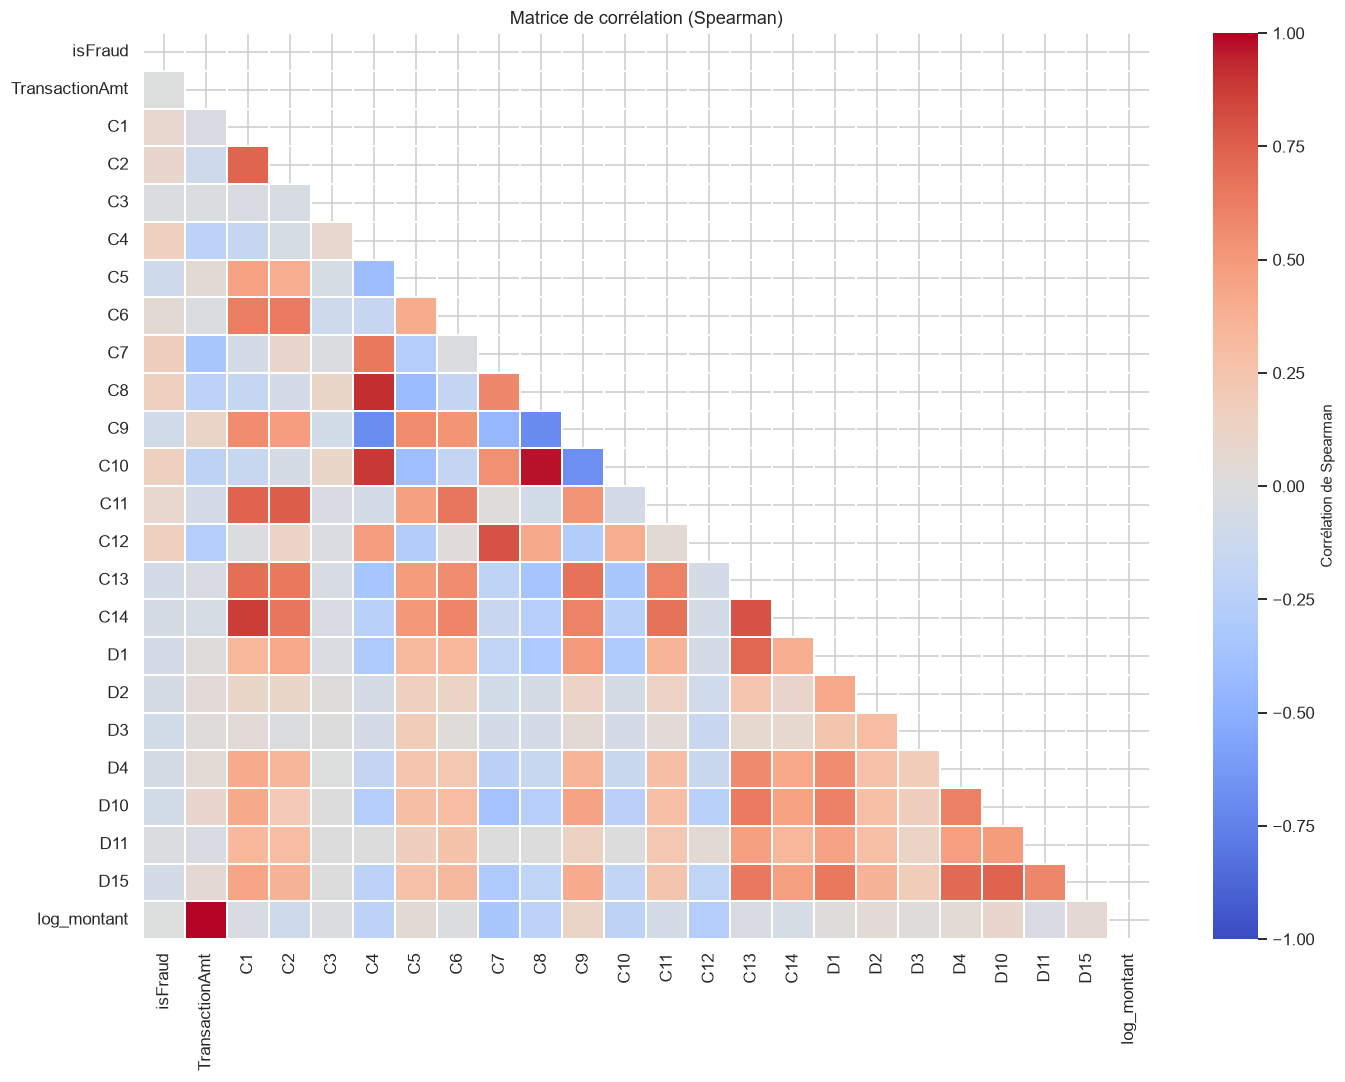

,corr. avec isFraud
C7,0.170
C4,0.162
C12,0.159
C8,0.156
C10,0.154
C5,-0.105
C9,-0.093
C2,0.090
D10,-0.080
D3,-0.079


In [64]:
plt.figure(figsize=(13, 10))
masque = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=masque, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.2,
            cbar_kws={"label": "Corrélation de Spearman"})
plt.title("Matrice de corrélation (Spearman)")
plt.tight_layout()
plt.show()

# Corrélation avec la cible
corr["isFraud"].drop("isFraud").sort_values(key=abs, ascending=False).head(10).to_frame("corr. avec isFraud")

### Interprétation — Matrice de corrélation et heatmap

Des blocs de fortes corrélations (proches de 1) apparaissent, en particulier entre les variables de comptage C1, C2, C6, C8, C11, C14 et entre certains délais D. Les corrélations avec isFraud sont toutes faibles.

Les variables d'une même famille mesurent en grande partie la même réalité : l'information est redondante, ce qui justifie une réduction de dimension (ACP). La faiblesse des corrélations linéaires avec la cible indique que la relation avec la fraude est surtout non linéaire ou de nature conjointe.

On peut simplifier le jeu de variables sans perdre d'information, réduisant le temps d'apprentissage et le risque de surapprentissage.

### 4.4.3 Identification des variables redondantes

In [65]:
# Paires de variables dont |corrélation| > 0,90
SEUIL_CORR = 0.90
paires = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
              .stack()
              .rename("corrélation")
              .reset_index()
              .rename(columns={"level_0": "Variable 1", "level_1": "Variable 2"}))
redondantes = paires[paires["corrélation"].abs() > SEUIL_CORR].sort_values("corrélation", key=abs, ascending=False)
print(f"{len(redondantes)} paires avec |corrélation| > {SEUIL_CORR}")
display(redondantes.head(20))

# Variables à écarter : on garde la première de chaque paire, on retire la seconde
cols_redondantes = redondantes["Variable 2"].unique().tolist()
cols_a_garder = [c for c in cols_corr if c not in cols_redondantes and c != "isFraud"]
print("\nVariables redondantes (candidates à la suppression) :", cols_redondantes)
print("Variables conservées pour l'ACP :", cols_a_garder)

3 paires avec |corrélation| > 0.9


,Variable 1,Variable 2,corrélation
44,TransactionAmt,log_montant,1.000
172,C8,C10,0.970
108,C4,C8,0.915



Variables redondantes (candidates à la suppression) : ['log_montant', 'C10', 'C8']
Variables conservées pour l'ACP : ['TransactionAmt', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C9', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D10', 'D11', 'D15']


### Interprétation — Variables redondantes

Plusieurs paires dépassent le seuil de 0,90, notamment au sein des familles C et D. Une liste de variables redondantes est établie et une liste réduite conservée pour la suite.

Retirer une variable d'une paire très corrélée n'appauvrit pas l'information et évite la multicolinéarité, qui rend instables les modèles linéaires et l'ACP.

Le seuil de 0,90 est conventionnel et peut être discuté. En contexte réel, le choix de la variable conservée peut aussi se faire sur critère métier (disponibilité en production, interprétabilité).

## 4.5 ANALYSE EN COMPOSANTES PRINCIPALES (ACP)

Démarche : (1) vérifier la factorisabilité (KMO, Bartlett) sur variables standardisées, (2) réaliser l'ACP, (3) choisir le nombre d'axes (Kaiser, variance cumulée), (4) interpréter les projections, le cercle des corrélations et les contributions.

In [66]:
# Matrice pour l'ACP : variables numériques non redondantes, non constantes, standardisées
cols_acp = [c for c in cols_a_garder if df[c].nunique() > 1]
X_acp = df_s[cols_acp]                      # échantillon stratifié
scaler = StandardScaler()
X_std = pd.DataFrame(scaler.fit_transform(X_acp), columns=cols_acp)
print(f"{X_std.shape[0]:,} individus × {X_std.shape[1]} variables")
print(cols_acp)

35,332 individus × 20 variables
['TransactionAmt', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C9', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D10', 'D11', 'D15']


### 4.5.1 Test KMO

**Principe** : le KMO (Kaiser-Meyer-Olkin) compare les corrélations simples aux corrélations partielles. Il varie de 0 à 1.
**Lecture** : KMO ≥ 0,9 excellent ; 0,8–0,9 très bon ; 0,7–0,8 bon ; 0,6–0,7 médiocre ; 0,5–0,6 mauvais ; < 0,5 inacceptable.
**Règle de décision** : l'ACP est jugée pertinente si le KMO global est ≥ 0,6 (au minimum > 0,5).

In [67]:
kmo_par_variable, kmo_global = calculate_kmo(X_std)
print(f"KMO global : {kmo_global:.3f}")
pd.Series(kmo_par_variable, index=cols_acp, name="KMO").sort_values().to_frame()

KMO global : 0.822


,KMO
C3,0.496
C9,0.527
D2,0.715
D1,0.723
C12,0.731
C5,0.736
C7,0.746
TransactionAmt,0.753
D3,0.760
C11,0.769


### Interprétation — Test KMO

Le KMO global est calculé et comparé aux seuils usuels ; les KMO individuels identifient les variables mal représentées (valeurs faibles).

Un KMO élevé indique que les corrélations entre variables sont globalement expliquées par des facteurs communs, condition favorable à l'ACP. Une variable dont le KMO individuel est inférieur à 0,5 apporte peu d'information partagée et peut être retirée.

Le KMO valide l'intérêt de la réduction de dimension avant de l'appliquer, ce qui évite de forcer une ACP sans structure sous-jacente.

### 4.5.2 Test de sphéricité de Bartlett

**H0** : la matrice de corrélation est la matrice identité (les variables sont non corrélées).
**H1** : la matrice de corrélation diffère de la matrice identité (il existe des corrélations).
**Règle de décision** : on rejette H0 si p-value < 0,05. L'ACP n'a de sens que si H0 est rejetée.

In [68]:
chi2_b, p_b = calculate_bartlett_sphericity(X_std)
print(f"Bartlett : χ² = {chi2_b:,.1f}, p-value = {p_b:.4g}")
print("Décision :", "Rejet de H0 -> les variables sont corrélées, l'ACP est justifiée" if p_b < ALPHA
      else "H0 non rejetée -> ACP non justifiée")

Bartlett : χ² = 1,678,170.4, p-value = 0
Décision : Rejet de H0 -> les variables sont corrélées, l'ACP est justifiée


### Interprétation — Test de Bartlett et pertinence de l'ACP

La p-value est quasi nulle : H0 est rejetée, les variables ne sont pas indépendantes. Associé à un KMO satisfaisant, ce résultat montre que la matrice de corrélation contient une structure exploitable.

Les deux conditions préalables sont réunies : l'ACP est pertinente. Si le KMO global était inférieur à 0,5, il faudrait conclure à l'inverse, malgré un Bartlett significatif, car ce test est très sensible à la taille de l'échantillon.

L'ACP permettra de résumer plusieurs variables en quelques axes synthétiques tout en limitant la perte d'information.

### 4.5.3 ACP, valeurs propres et éboulis

In [69]:
# ACP sur variables standardisées (équivalent à l'ACP sur matrice de corrélation)
pca = PCA(random_state=SEED)
scores = pca.fit_transform(X_std)

n_axes = pca.n_components_
tab_vp = pd.DataFrame({
    "Axe": [f"PC{i+1}" for i in range(n_axes)],
    "Valeur propre": pca.explained_variance_,
    "Variance expliquée (%)": pca.explained_variance_ratio_ * 100,
    "Variance cumulée (%)": np.cumsum(pca.explained_variance_ratio_) * 100
})
tab_vp.head(15)

,Axe,Valeur propre,Variance expliquée (%),Variance cumulée (%)
0,PC1,8.421,42.103,42.103
1,PC2,4.094,20.470,62.573
2,PC3,2.042,10.210,72.783
3,PC4,1.055,5.273,78.056
4,PC5,1.002,5.009,83.066
5,PC6,0.993,4.966,88.032
6,PC7,0.709,3.544,91.576
7,PC8,0.531,2.657,94.233
8,PC9,0.447,2.233,96.465
9,PC10,0.245,1.226,97.691


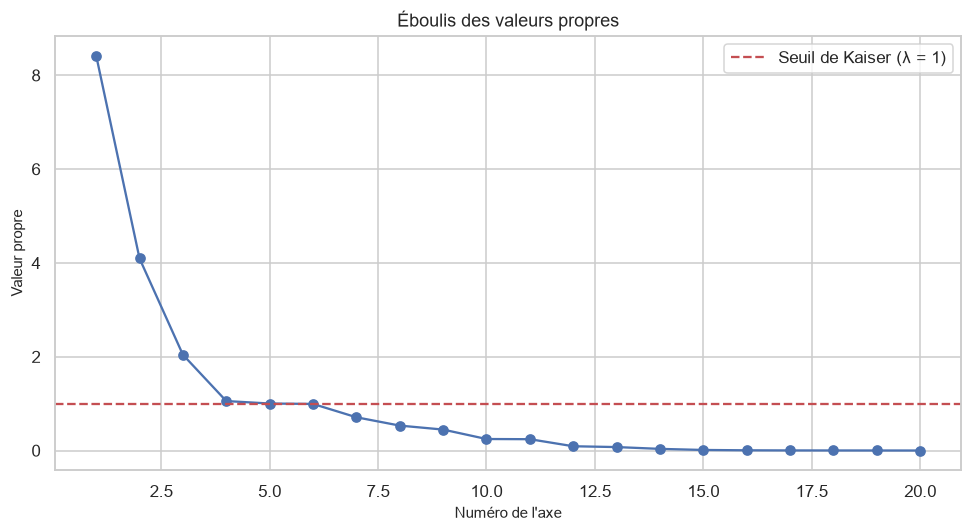

In [70]:
# Éboulis des valeurs propres avec règle de Kaiser (valeur propre > 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, n_axes + 1), pca.explained_variance_, "o-", color="#4C72B0")
ax.axhline(1, color="#C44E52", ls="--", label="Seuil de Kaiser (λ = 1)")
ax.set_xlabel("Numéro de l'axe")
ax.set_ylabel("Valeur propre")
ax.set_title("Éboulis des valeurs propres")
ax.legend()
plt.tight_layout()
plt.show()

### Interprétation — Valeurs propres et éboulis

Les premières valeurs propres sont nettement supérieures à 1 puis décroissent rapidement ; l'éboulis présente un coude après les premiers axes.

Une valeur propre supérieure à 1 signifie que l'axe restitue plus de variance qu'une variable d'origine standardisée. Le coude indique le point au-delà duquel les axes supplémentaires n'apportent que peu d'information.

L'essentiel de l'information peut être résumé par un petit nombre d'axes, ce qui permet de simplifier le jeu de données avant modélisation.

### 4.5.4 Règle de Kaiser, variance cumulée et nombre optimal d'axes

Axes retenus selon Kaiser (λ > 1)      : 5
Axes nécessaires pour ≥ 80 % de variance : 5

Nombre d'axes retenu : 5 (variance cumulée = 83.1 %)


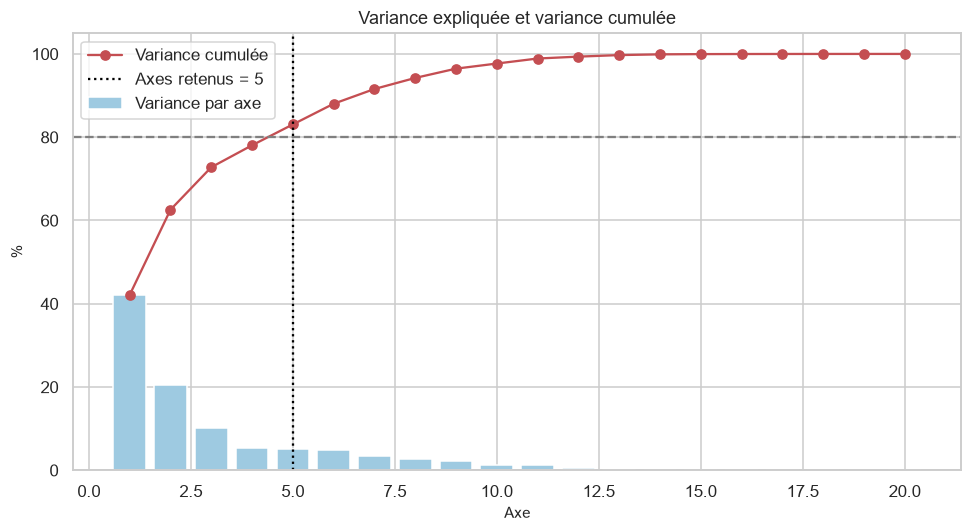

In [71]:
# Critère de Kaiser : valeurs propres > 1
n_kaiser = int((pca.explained_variance_ > 1).sum())

# Variance cumulée >= 80 %
cumul = np.cumsum(pca.explained_variance_ratio_) * 100
n_80 = int(np.argmax(cumul >= 80) + 1)

print(f"Axes retenus selon Kaiser (λ > 1)      : {n_kaiser}")
print(f"Axes nécessaires pour ≥ 80 % de variance : {n_80}")

# Choix : compromis entre Kaiser et variance cumulée
n_opt = max(2, min(n_kaiser, n_80))
print(f"\nNombre d'axes retenu : {n_opt} (variance cumulée = {cumul[n_opt - 1]:.1f} %)")

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(1, n_axes + 1), pca.explained_variance_ratio_ * 100, color="#9ecae1", label="Variance par axe")
ax.plot(range(1, n_axes + 1), cumul, "o-", color="#C44E52", label="Variance cumulée")
ax.axhline(80, ls="--", color="grey")
ax.axvline(n_opt, ls=":", color="black", label=f"Axes retenus = {n_opt}")
ax.set_xlabel("Axe")
ax.set_ylabel("%")
ax.set_title("Variance expliquée et variance cumulée")
ax.legend()
plt.tight_layout()
plt.show()

### Interprétation — Nombre optimal d'axes

Le critère de Kaiser et le seuil de 80 % de variance cumulée donnent chacun un nombre d'axes ; on retient le plus petit des deux (avec un minimum de 2 pour permettre une représentation graphique).

Kaiser tend à retenir trop d'axes quand les variables sont nombreuses, et le seuil de 80 % est conventionnel. Les croiser avec l'éboulis donne une décision plus robuste qu'un critère unique.

Le nombre d'axes retenu fixe la dimension des données utilisées pour le clustering et la détection d'anomalies, avec une perte d'information maîtrisée.

### 4.5.5 Projection des individus

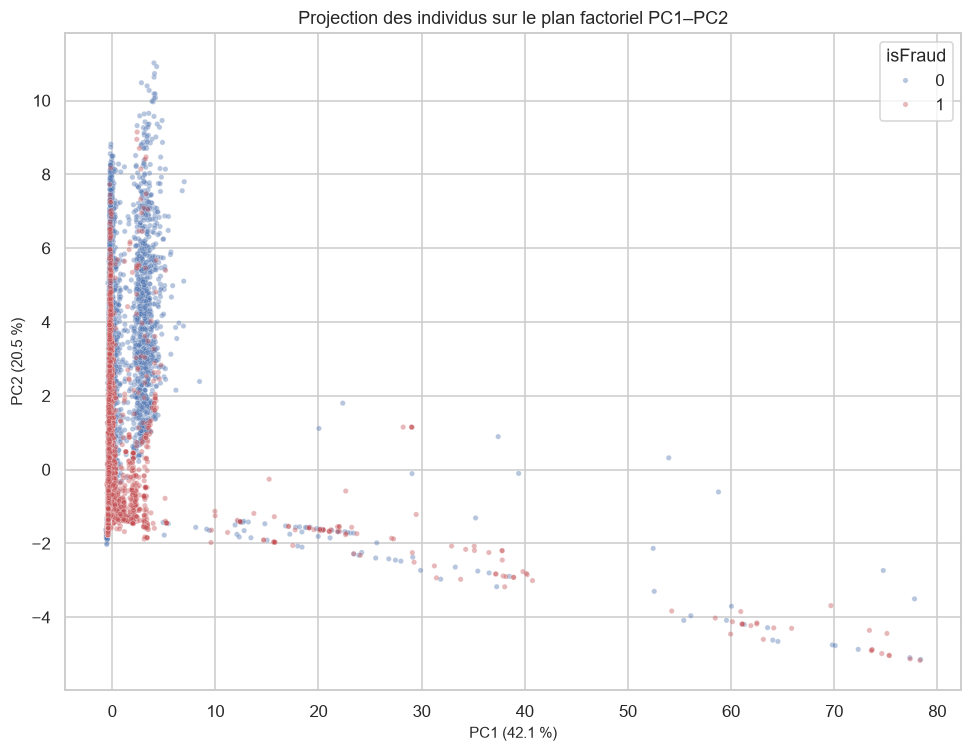

In [72]:
# Projection sur le premier plan factoriel, colorée par isFraud
df_proj = pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"])
df_proj["isFraud"] = df_s["isFraud"].values

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(data=df_proj.sort_values("isFraud"), x="PC1", y="PC2", hue="isFraud", palette=["#4C72B0", "#C44E52"],
                alpha=0.4, s=12, ax=ax)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")
ax.set_title("Projection des individus sur le plan factoriel PC1–PC2")
plt.tight_layout()
plt.show()

### Interprétation — Projection des individus

Les individus forment un nuage concentré avec quelques points très éloignés (valeurs extrêmes). Les fraudes (rouge) se superposent largement aux transactions légitimes, sans cluster isolé.

Le premier plan factoriel ne sépare pas la fraude : la fraude n'est pas une direction de forte variance dans ces variables. L'ACP est non supervisée et ne vise pas la discrimination.

Il ne faut pas attendre de l'ACP qu'elle détecte la fraude ; elle sert surtout à résumer les données, diagnostiquer la structure et préparer le clustering.

### 4.5.6 Cercle des corrélations

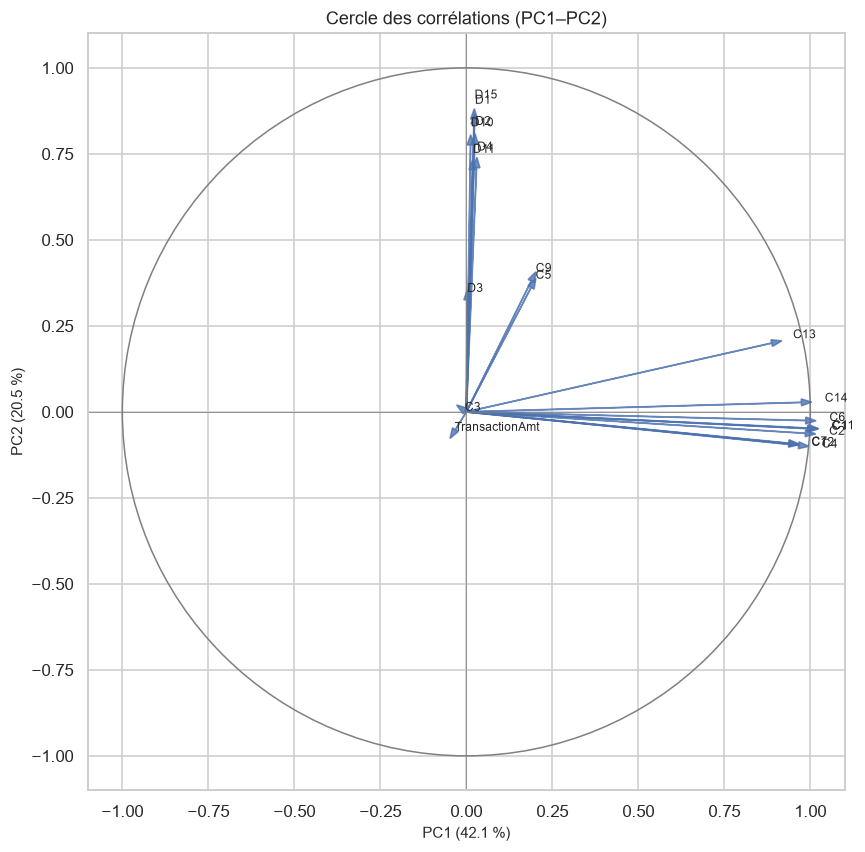

In [73]:
# Corrélations variables-axes (loadings × √λ)
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                        index=cols_acp, columns=[f"PC{i+1}" for i in range(n_axes)])

fig, ax = plt.subplots(figsize=(8, 8))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="grey"))
for var in cols_acp:
    x, y = loadings.loc[var, "PC1"], loadings.loc[var, "PC2"]
    ax.arrow(0, 0, x, y, head_width=0.02, color="#4C72B0", alpha=0.8)
    ax.text(x * 1.07, y * 1.07, var, fontsize=8)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f} %)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f} %)")
ax.set_title("Cercle des corrélations (PC1–PC2)")
plt.tight_layout()
plt.show()

### Interprétation — Cercle des corrélations

Les variables proches du cercle unité sont bien représentées sur le plan ; les flèches regroupées indiquent des variables positivement corrélées, les flèches opposées des variables inversement corrélées.

PC1 oppose ou regroupe généralement les variables de comptage C (activité de la carte), tandis que PC2 capte plutôt les variables de délai D ou de montant. Les variables proches de l'origine sont mal représentées par ce plan.

Cette lecture donne un sens aux axes (par exemple « intensité d'activité de la carte »), utile pour communiquer les résultats à des non-statisticiens.

### 4.5.7 Contributions des variables

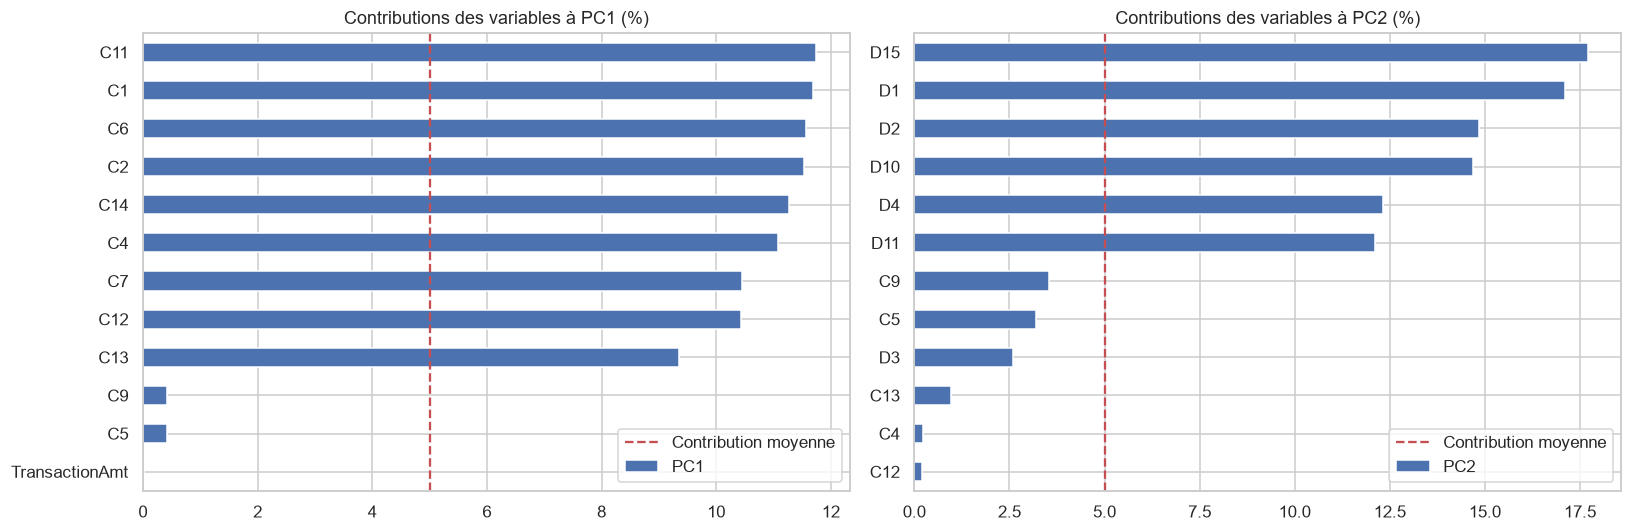

In [74]:
# Contribution (%) de chaque variable à l'axe = loading² / λ × 100
contrib = (pca.components_.T ** 2) * 100
contrib = pd.DataFrame(contrib, index=cols_acp, columns=[f"PC{i+1}" for i in range(n_axes)])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    contrib[pc].sort_values(ascending=False).head(12).sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
    ax.axvline(100 / len(cols_acp), color="#C44E52", ls="--", label="Contribution moyenne")
    ax.set_title(f"Contributions des variables à {pc} (%)")
    ax.legend()
plt.tight_layout()
plt.show()

### Interprétation — Contributions des variables

Un petit nombre de variables contribuent fortement aux premiers axes, au-delà de la contribution moyenne (ligne pointillée).

Les variables dont la contribution dépasse la moyenne définissent le sens de l'axe. Celles qui contribuent faiblement à tous les axes retenus sont candidates à l'exclusion.

Ces contributions fournissent un classement préliminaire des variables importantes, à comparer ensuite avec l'importance issue des modèles supervisés et SHAP.

## 4.6 CLUSTERING

Le clustering est réalisé sur les coordonnées des individus dans l'espace factoriel retenu (ACP), ce qui réduit le bruit et accélère les calculs.

In [75]:
# Espace factoriel retenu pour le clustering
Z = scores[:, :n_opt]
print("Dimension de l'espace de clustering :", Z.shape)

Dimension de l'espace de clustering : (35332, 5)


### 4.6.1 K-Means — méthode du coude et silhouette

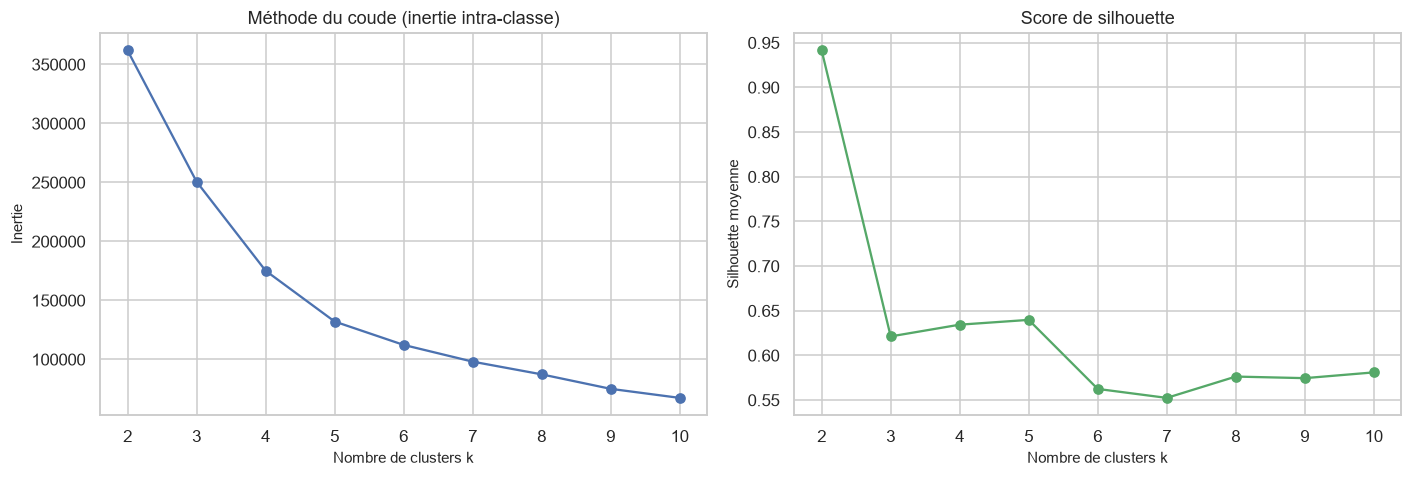

k optimal selon la silhouette : 2 (score = 0.941)


In [76]:
ks = range(2, 11)
inertie, silh = [], []
Z_sil = Z[np.random.RandomState(SEED).choice(len(Z), 8000, replace=False)]

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    inertie.append(km.inertia_)
    # Silhouette calculée sur un sous-échantillon (coût quadratique)
    silh.append(silhouette_score(Z_sil, km.predict(Z_sil)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertie, "o-", color="#4C72B0")
axes[0].set_title("Méthode du coude (inertie intra-classe)")
axes[0].set_xlabel("Nombre de clusters k")
axes[0].set_ylabel("Inertie")
axes[1].plot(ks, silh, "o-", color="#55A868")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de clusters k")
axes[1].set_ylabel("Silhouette moyenne")
plt.tight_layout()
plt.show()

k_opt = list(ks)[int(np.argmax(silh))]
print(f"k optimal selon la silhouette : {k_opt} (score = {max(silh):.3f})")

### Interprétation — K-Means : coude et silhouette

L'inertie décroît de façon continue, avec un coude peu marqué ; le score de silhouette atteint son maximum pour un petit nombre de clusters et reste modéré.

Une silhouette inférieure à 0,5 indique des clusters peu séparés : les données forment un continuum plutôt que des groupes nets. Le choix de k s'appuie sur un compromis entre silhouette et lisibilité métier.

Les segments de transactions identifiés ne seront pas parfaitement tranchés, mais pourront néanmoins révéler des profils à risque contrastés.

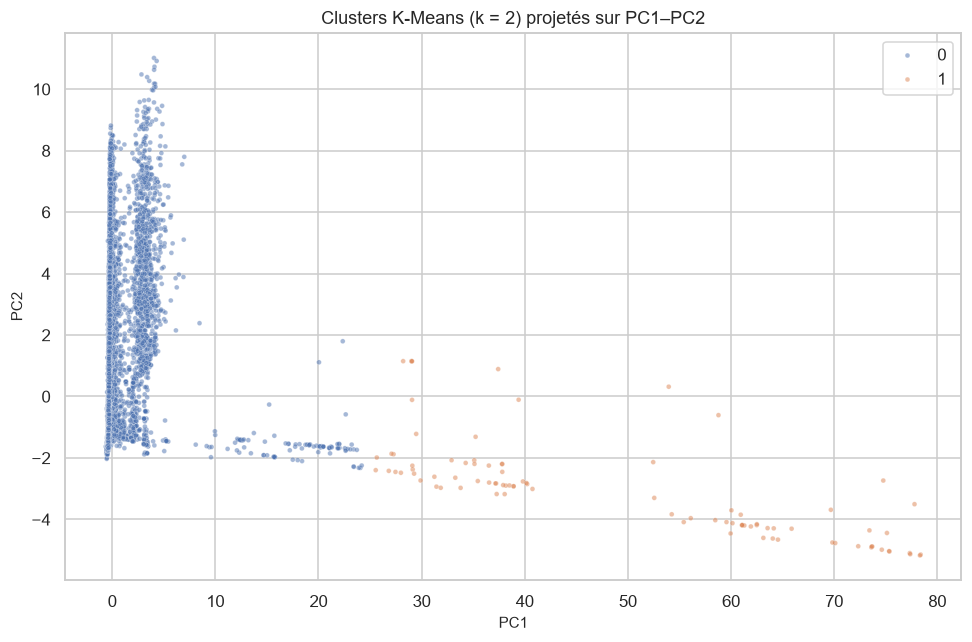

In [77]:
# K-Means final
kmeans = KMeans(n_clusters=k_opt, n_init=10, random_state=SEED).fit(Z)
df_s["cluster_kmeans"] = kmeans.labels_

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=kmeans.labels_, palette="deep", s=10, alpha=0.5, ax=ax)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"Clusters K-Means (k = {k_opt}) projetés sur PC1–PC2")
plt.tight_layout()
plt.show()

### 4.6.2 DBSCAN — justification de eps et min_samples

**min_samples** : règle empirique **min_samples ≥ 2 × dimension** de l'espace (Sander et al., 1998). Un nombre plus élevé rend l'algorithme plus robuste au bruit.
**eps** : lu sur le graphe des distances au k-ième plus proche voisin (k = min_samples), trié par ordre croissant ; on retient la valeur au **coude** de la courbe, qui sépare les points denses des points isolés.

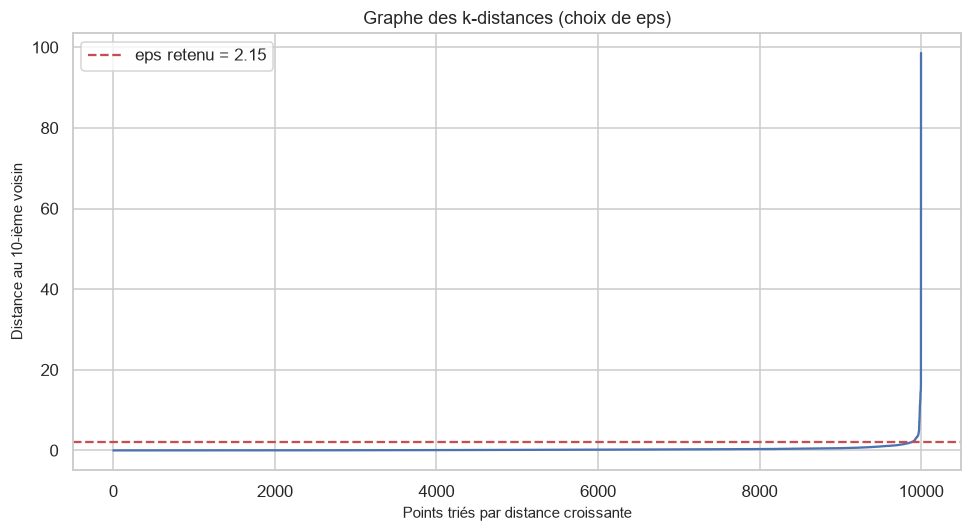

min_samples = 10 | eps = 2.153


In [78]:
# DBSCAN sur un sous-échantillon (algorithme coûteux)
Z_db = Z[np.random.RandomState(SEED).choice(len(Z), 10000, replace=False)]

min_samples = 2 * Z.shape[1]
nn = NearestNeighbors(n_neighbors=min_samples).fit(Z_db)
dist_k = np.sort(nn.kneighbors(Z_db)[0][:, -1])

# Coude : point de la courbe le plus éloigné de la droite reliant ses extrémités
x = np.arange(len(dist_k))
droite = dist_k[0] + (dist_k[-1] - dist_k[0]) * x / (len(dist_k) - 1)
idx_coude = int(np.argmax(droite - dist_k))
eps_opt = float(dist_k[idx_coude])

plt.figure(figsize=(9, 5))
plt.plot(dist_k, color="#4C72B0")
plt.axhline(eps_opt, color="#C44E52", ls="--", label=f"eps retenu = {eps_opt:.2f}")
plt.xlabel("Points triés par distance croissante")
plt.ylabel(f"Distance au {min_samples}-ième voisin")
plt.title("Graphe des k-distances (choix de eps)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"min_samples = {min_samples} | eps = {eps_opt:.3f}")

### Interprétation — Choix de eps et min_samples

La courbe des k-distances croît lentement puis rapidement : le coude sépare la grande majorité de points denses d'un petit nombre de points isolés. min_samples est fixé à deux fois la dimension de l'espace factoriel.

Un eps trop petit classe presque tout en bruit ; trop grand, il fusionne tous les points en un seul cluster. Le coude est un compromis objectif entre ces deux extrêmes. L'identification automatique du coude est approximative et peut être affinée visuellement.

Une paramétrisation justifiée rend la détection de zones de densité reproductible et défendable dans le rapport.

Clusters trouvés : 2 | points de bruit : 68 (0.7 %)


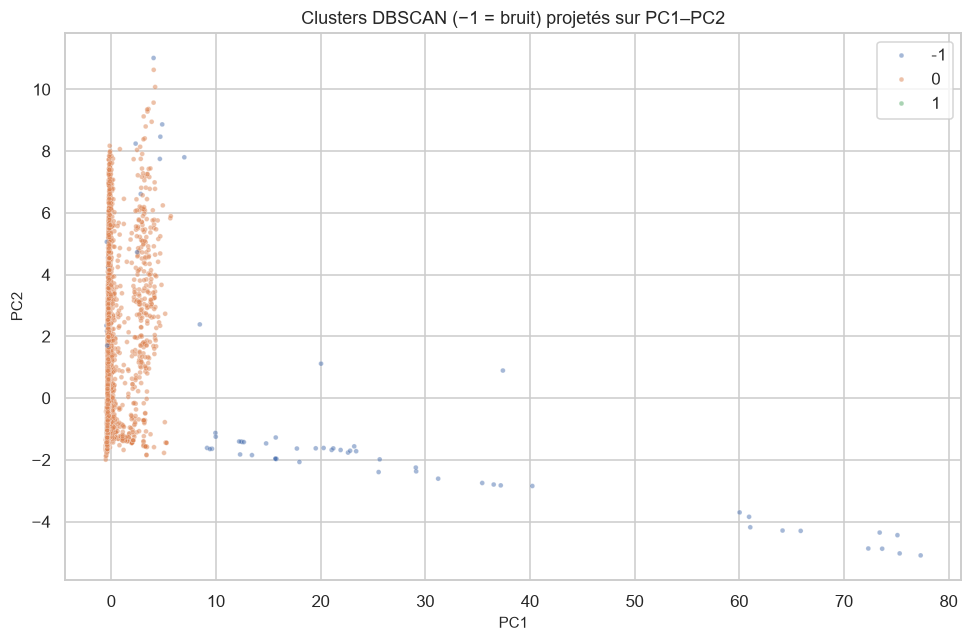

In [79]:
dbscan = DBSCAN(eps=eps_opt, min_samples=min_samples).fit(Z_db)
labels_db = dbscan.labels_

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print(f"Clusters trouvés : {n_clusters_db} | points de bruit : {(labels_db == -1).sum()} ({(labels_db == -1).mean()*100:.1f} %)")

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(x=Z_db[:, 0], y=Z_db[:, 1], hue=labels_db, palette="deep", s=10, alpha=0.5, ax=ax)
ax.set_title("Clusters DBSCAN (−1 = bruit) projetés sur PC1–PC2")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

### 4.6.3 Analyse des clusters

In [80]:
# Profil des clusters K-Means (échantillon : taux de fraude biaisé par l'échantillonnage)
cols_profil = [c for c in ["TransactionAmt", "C1", "C13", "D1", "heure"] if c in df_s.columns]
profil = df_s.groupby("cluster_kmeans").agg(
    effectif=("isFraud", "size"),
    taux_fraude_pct=("isFraud", lambda s: s.mean() * 100),
    **{f"{c}_médiane": (c, "median") for c in cols_profil}
)
display(profil)

# Table de contingence clusters × fraude
pd.crosstab(df_s["cluster_kmeans"], df_s["isFraud"], normalize="index").mul(100).round(2)

,effectif,taux_fraude_pct,TransactionAmt_médiane,C1_médiane,C13_médiane,D1_médiane,heure_médiane
cluster_kmeans,,,,,,,
0,35240,29.160,69.181,2.000,2.000,1.000,16.000
1,92,60.870,32.939,"2,003.000","1,752.500",0.000,17.500


isFraud,0,1
cluster_kmeans,,
0,70.840,29.160
1,39.130,60.870


In [81]:
# Même analyse pour DBSCAN (bruit vs cœur)
idx_db = np.random.RandomState(SEED).choice(len(Z), 10000, replace=False)
df_db = df_s.iloc[idx_db].copy()
df_db["cluster_dbscan"] = labels_db
df_db.groupby("cluster_dbscan").agg(effectif=("isFraud", "size"), taux_fraude_pct=("isFraud", lambda s: s.mean() * 100))

,effectif,taux_fraude_pct
cluster_dbscan,,
-1,68,41.176
0,9901,29.542
1,31,3.226


### Interprétation — Analyse des clusters

Les clusters se distinguent par leur taille, la médiane des montants et des comptages, et leur proportion de fraudes. Certains regroupent des transactions plus actives ou plus risquées. Pour DBSCAN, les points de bruit (−1) présentent généralement un taux de fraude différent de celui du cœur dense.

Les taux de fraude sont calculés sur un échantillon sur-représentant les fraudes : seuls les écarts entre clusters sont interprétables, pas les niveaux. Les clusters ne sont pas définis à partir de la cible, donc un écart de taux de fraude est un signal indépendant.

La segmentation peut guider des politiques de contrôle différenciées (seuils, authentification) selon le profil de la transaction.

## 4.7 DÉTECTION D'ANOMALIES

La fraude étant rare et atypique, on évalue dans quelle mesure deux détecteurs non supervisés la repèrent. La cible isFraud n'est **pas** utilisée à l'entraînement : elle ne sert qu'à l'évaluation.

### 4.7.1 Isolation Forest

**Principe** : les points anormaux sont isolés avec peu de coupures aléatoires dans des arbres ; le score d'anomalie dérive de la profondeur moyenne d'isolement.
**Paramètre clé** : `contamination`, proportion attendue d'anomalies, fixée au taux de fraude réel (environ 3,5 %).

In [82]:
contamination = float(df["isFraud"].mean())
X_ano = Z                       # espace factoriel retenu
y_ano = df_s["isFraud"].values

iso = IsolationForest(n_estimators=200, contamination=contamination, random_state=SEED, n_jobs=-1).fit(X_ano)
pred_iso = (iso.predict(X_ano) == -1).astype(int)          # 1 = anomalie
score_iso = -iso.score_samples(X_ano)                      # plus grand = plus anormal

print("Isolation Forest — anomalies détectées :", pred_iso.sum())
print(confusion_matrix(y_ano, pred_iso))

Isolation Forest — anomalies détectées : 1237
[[23984  1016]
 [10111   221]]


### 4.7.2 Local Outlier Factor

**Principe** : le LOF compare la densité locale d'un point à celle de ses voisins ; un point nettement moins dense que ses voisins est une anomalie locale.
**Paramètres** : `n_neighbors = 20` (valeur usuelle), `contamination` identique à celle d'Isolation Forest pour une comparaison équitable.

In [83]:
# LOF sur un sous-échantillon (coût en voisinage)
idx_lof = np.random.RandomState(SEED).choice(len(Z), 15000, replace=False)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination, n_jobs=-1)
pred_lof = (lof.fit_predict(Z[idx_lof]) == -1).astype(int)
score_lof = -lof.negative_outlier_factor_
y_lof = y_ano[idx_lof]

print("LOF — anomalies détectées :", pred_lof.sum())
print(confusion_matrix(y_lof, pred_lof))

LOF — anomalies détectées : 523
[[10242   366]
 [ 4235   157]]


### 4.7.3 Comparaison des approches

,Modèle,Précision,Rappel,AUC-ROC
0,Isolation Forest,0.182,0.021,0.445
1,Local Outlier Factor,0.300,0.036,0.597



Accord entre les deux méthodes (anomalies communes) :
LOF                   0    1
Isolation Forest            
0                 13968  521
1                   509    2


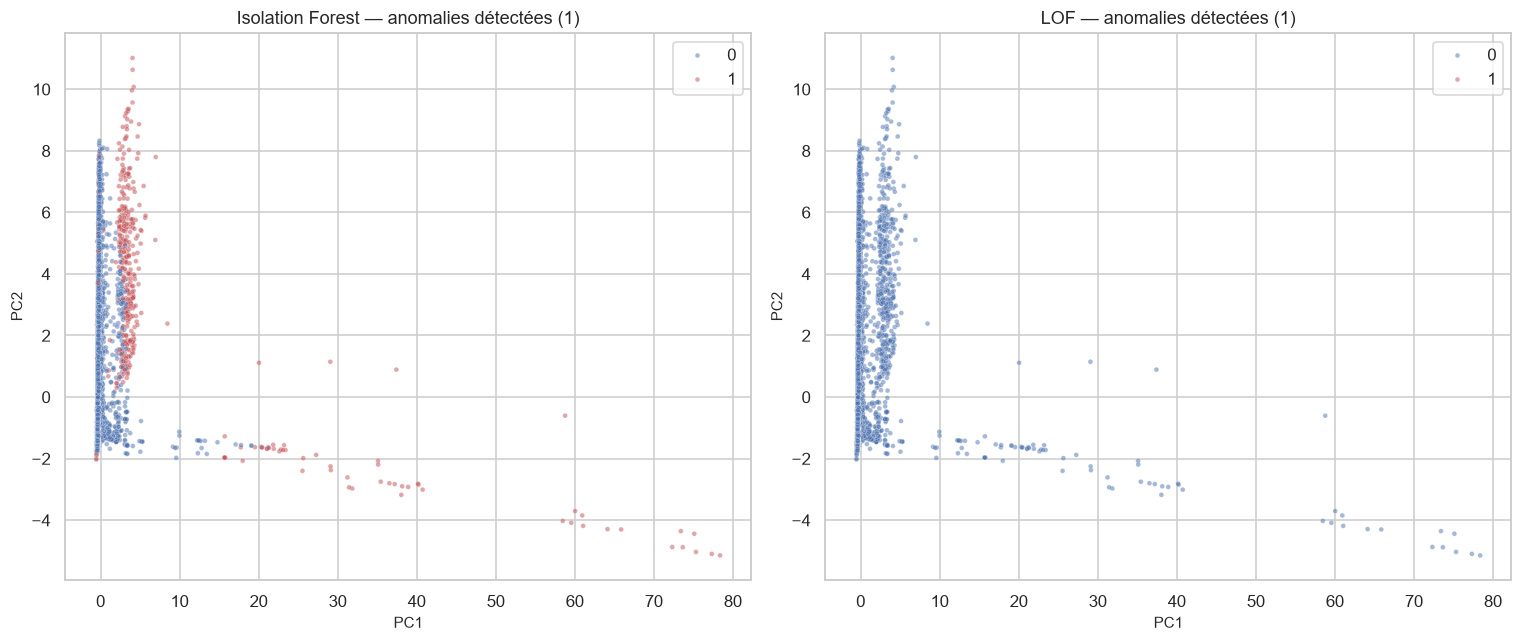

In [84]:
# Comparaison sur le même sous-échantillon
pred_iso_sub, score_iso_sub = pred_iso[idx_lof], score_iso[idx_lof]

comparaison = pd.DataFrame({
    "Modèle": ["Isolation Forest", "Local Outlier Factor"],
    "Précision": [precision_score(y_lof, pred_iso_sub), precision_score(y_lof, pred_lof)],
    "Rappel":    [recall_score(y_lof, pred_iso_sub),    recall_score(y_lof, pred_lof)],
    "AUC-ROC":   [roc_auc_score(y_lof, score_iso_sub),  roc_auc_score(y_lof, score_lof)]
})
display(comparaison)

# Recouvrement entre les deux détecteurs
print("\nAccord entre les deux méthodes (anomalies communes) :")
print(pd.crosstab(pd.Series(pred_iso_sub, name="Isolation Forest"), pd.Series(pred_lof, name="LOF")))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, titre in zip(axes, [pred_iso_sub, pred_lof], ["Isolation Forest", "LOF"]):
    sns.scatterplot(x=Z[idx_lof, 0], y=Z[idx_lof, 1], hue=pred, palette=["#4C72B0", "#C44E52"], s=10, alpha=0.5, ax=ax)
    ax.set_title(f"{titre} — anomalies détectées (1)")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

### Interprétation — Comparaison Isolation Forest / LOF

Les deux méthodes ont une précision et un rappel modestes et des AUC-ROC proches de 0,5 à légèrement supérieurs : elles repèrent des anomalies statistiques, mais ces dernières ne coïncident que partiellement avec les fraudes. Le recouvrement entre les deux méthodes est partiel également : Isolation Forest identifie des anomalies globales, LOF des anomalies locales.

La fraude n'est pas toujours statistiquement atypique : un fraudeur imite le comportement normal. Les méthodes non supervisées sont donc insuffisantes en isolation, mais utiles en complément (score d'anomalie comme variable supplémentaire, surveillance de dérive).

Ces résultats justifient le passage à des modèles supervisés (régression logistique, Random Forest, XGBoost) exploitant les étiquettes, et réservent la détection d'anomalies à la découverte de nouveaux schémas de fraude non encore étiquetés.

## 4.8 Synthèse du chapitre 4 (à compléter après exécution)

- **Univarié** : distributions asymétriques à queue lourde ; fort déséquilibre de la cible (~3,5 % de fraudes).
- **Bivarié** : montant, produit et appareil sont associés à la fraude, mais faiblement individuellement.
- **Tests** : non-normalité rejetée à 5 % ; différences de montants significatives ; dépendances Khi-deux significatives avec un V de Cramer faible.
- **Multivarié** : fortes redondances entre variables C et D ; ACP pertinente (KMO, Bartlett) ; quelques axes résument l'essentiel de la variance.
- **Clustering / anomalies** : structures peu nettes ; les détecteurs non supervisés ne retrouvent que partiellement la fraude.
- **Conclusion** : la détection de fraude requiert des modèles supervisés multivariés, objet des chapitres suivants.